In [ ]:
# 查看当前挂载的数据集目录, 该目录下的变更重启环境后会自动还原
# View dataset directory. 
# This directory will be recovered automatically after resetting environment. 
!ls /home/aistudio/data

In [ ]:
# 查看工作区文件, 该目录下的变更将会持久保存. 请及时清理不必要的文件, 避免加载过慢.
# View personal work directory. 
# All changes under this directory will be kept even after reset. 
# Please clean unnecessary files in time to speed up environment loading. 
!ls /home/aistudio/work

In [ ]:
# 如果需要进行持久化安装, 需要使用持久化路径, 如下方代码示例:
# If a persistence installation is required, 
# you need to use the persistence path as the following: 
#!mkdir /home/aistudio/external-libraries
#!pip install scikit-image -t /home/aistudio/external-libraries

In [6]:
#!pip install ipywidgets -t /home/aistudio/external-libr
#!pip install widgetsnbextension -t /home/aistudio/external-libr  
#!pip install --upgrade ipykernel ipywidgets

In [7]:
#!pip install ipympl -t /home/aistudio/external-libraries

In [5]:
#!pip list

In [21]:
# 同时添加如下代码, 这样每次环境(kernel)启动的时候只要运行下方代码即可: 
# Also add the following code, 
# so that every time the environment (kernel) starts, 
# just run the following code: 
import sys 
sys.path.append('/home/aistudio/external-libraries')

# example9-1 Roberts算子

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

plt.hist(gray.ravel(),bins =256,range=[0,256])
plt.show()

kx = np.array([[-1,0],[0,1]],dtype=np.float64)
ky = np.array([[0,-1],[1,0]],dtype = np.float64)
print(kx)
print(kx.dtype)
print(ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)


n,bins,_ = plt.hist(Gx.ravel(),bins=100,range=[-255,256])
plt.show()
print(n) 
print(bins)
plt.imshow(Gx,cmap='gray')
plt.show()
plt.imshow(np.abs(Gx),cmap='gray')
plt.show()

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)
G1 = np.sqrt(Gx*Gx + Gy*Gy)
plt.imshow(G1,cmap = 'gray')
plt.show()
print(Gx)
print(Gy)
print(Gx.dtype)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2) = plt.subplots(1,3,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kx = np.array([[-1,0],[0,1]])
ky = np.array([[0,-1],[1,0]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0) # y = abs(alpha * x + beta) np.abs( alpha * x + beta)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0) # Gx * 0.5 + Gy * 0.5  + bias


G1 = np.sqrt(Gx*Gx + Gy*Gy)

plt.imshow(G1,cmap = 'gray')
plt.show()

print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-2 Prewitt operator

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-1,-1],[0,0,0],[1,1,1]])
kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2) = plt.subplots(1,3,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-1,-1],[0,0,0],[1,1,1]])
kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-3 Soble operator 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(kx,ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)


G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(kx)
print(ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)

Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

## cv2.Sobel

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(kx)
print(ky) 
#Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
#Gy = cv2.filter2D(gray,cv2.CV_64F,ky)
Gx = cv2.Sobel(gray,cv2.CV_64F,1,0,ksize = 1)
Gy = cv2.Sobel(gray,cv2.CV_64F,0,1,ksize = 1)


Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-8 Scharr operator

In [ ]:

ky = np.array([[-3,-10,-3],[0,0,0],[3,10,3]])
kx = np.array([[-3,0,3],[-10,0,10],[-3,0,3]])
a = ky.ravel()
print(a)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-3,-10,-3],[0,0,0],[3,10,3]])
kx = np.array([[-3,0,3],[-10,0,10],[-3,0,3]])
print(kx)
print(ky) 
Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
Gy = cv2.filter2D(gray,cv2.CV_64F,ky)
#Gx = cv2.Scharr(gray,cv2.CV_64F,1,0)
#Gy = cv2.Sobel(gray,cv2.CV_64F,0,1)

plt.hist(Gx.ravel(),bins=100,range=[-255*16,255*16])
plt.show()


Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)

#G = (Gx_abs + Gy_abs)/2.0
G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(G)
print(np.max(Gx),np.min(Gx))
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs/10,cmap = 'gray')
ax2.imshow(Gy_abs/10,cmap='gray')
ax3.imshow(G,cmap = 'gray')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

ky = np.array([[-3,-10,-3],[0,0,0],[3,10,3]])
kx = np.array([[-3,0,3],[-10,0,10],[-3,0,3]])
print(kx,ky) 
#Gx = cv2.filter2D(gray,cv2.CV_64F,kx)
#Gy = cv2.filter2D(gray,cv2.CV_64F,ky)
Gx = cv2.Scharr(gray,cv2.CV_64F,1,0)
Gy = cv2.Scharr(gray,cv2.CV_64F,0,1)
Gx_abs = cv2.convertScaleAbs(Gx,alpha=1,beta = 0)
# Gx_abs = np.abs(Gx_abs).astype(np.uint8)
Gy_abs = cv2.convertScaleAbs(Gy,alpha = 1,beta = 0)


G = cv2.addWeighted(Gx_abs,0.5,Gy_abs,0.5,0)
print(Gx)
print(Gy)

print(Gx_abs)
print(Gy_abs)
print(Gx_abs.dtype)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(Gx_abs,cmap = 'gray')
ax2.imshow(Gy_abs,cmap='gray')
ax3.imshow(G,cmap = 'gray')

# example 9-4 Laplacian Operator

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

G = cv2.filter2D(gray,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

print(kernel)
print(G)

fig,(ax0,ax1) = plt.subplots(1,2,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(G,cmap = 'gray')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))

gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

#G = cv2.filter2D(gray,cv2.CV_64F,kernel)

G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

print(kernel)
print(G)

fig,(ax0,ax1) = plt.subplots(1,2,figsize = (15,10),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(G,cmap = 'gray')


# example 9-5  first blur with gaussian then laplacian 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

G = cv2.filter2D(gray_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

print(kernel)
print(G)

fig,(ax0,ax1) = plt.subplots(1,2,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(G,cmap = 'gray')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray_noise)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

gk = cv2.getGaussianKernel(3,0)
gk = gk @ gk.T
#print(gk)

gray_remove_noise = cv2.filter2D(gray_noise,cv2.CV_64F,gk)
G = cv2.filter2D(gray_remove_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

#print(kernel)
#print(G)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(gray_noise,cmap = 'gray')
ax2.imshow(gray_remove_noise,cmap='gray')
ax3.imshow(G,cmap='gray')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray_noise)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

gk = cv2.getGaussianKernel(17,0)
gk = gk @ gk.T
#print(gk)

gray_remove_noise = cv2.filter2D(gray_noise,cv2.CV_64F,gk)
G = cv2.filter2D(gray_remove_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

#print(kernel)
#print(G)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(gray_noise,cmap = 'gray')
ax2.imshow(gray_remove_noise,cmap='gray')
ax3.imshow(G,cmap='gray')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
gray_noise = util.random_noise(gray,mode = 's&p')*255
print(gray_noise)

kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]])

gk = cv2.getGaussianKernel(31,0)
gk = gk @ gk.T
#print(gk)

gray_remove_noise = cv2.filter2D(gray_noise,cv2.CV_64F,gk)
G = cv2.filter2D(gray_remove_noise,cv2.CV_64F,kernel)

#G = cv2.Laplacian(gray,cv2.CV_64F)
G = cv2.convertScaleAbs(G,alpha = 1,beta = 0)

#print(kernel)
#print(G)

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize = (30,7),dpi = 100)
ax0.imshow(gray,cmap='gray')
ax1.imshow(gray_noise,cmap = 'gray')
ax2.imshow(gray_remove_noise,cmap='gray')
ax3.imshow(G,cmap='gray')


# example 9-10 Robinson operator 

## robinson eight operators

In [52]:
import numpy as np 
import cv2 
import matplotlib.pyplot as plt
N = np.array([[1,2,1],[0,0,0],[-1,-2,-1]])
S = np.flip(N,axis = 0)
E = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
W = np.flip(E,axis = 1)

NE = np.array([[0,1,2],[-1,0,1],[-2,-1,0]])
SW = np.flip(np.flip(NE,axis=0),axis = 1)

NW = np.array([[2,1,0],[1,0,-1],[0,-1,-2]])
SE = np.flip(np.flip(NW,axis = 0),axis = 1)
print('N:\n{}'.format(N) )
print('S:\n %s' %(S))
print('E:\n %s'%(S)) 
print('W:\n%s'%W)

print(NE) 
print(SW )

print(NW) 
print(SE) 

N:
[[ 1  2  1]
 [ 0  0  0]
 [-1 -2 -1]]
S:
 [[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
E:
 [[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
W:
[[ 1  0 -1]
 [ 2  0 -2]
 [ 1  0 -1]]
[[ 0  1  2]
 [-1  0  1]
 [-2 -1  0]]
[[ 0 -1 -2]
 [ 1  0 -1]
 [ 2  1  0]]
[[ 2  1  0]
 [ 1  0 -1]
 [ 0 -1 -2]]
[[-2 -1  0]
 [-1  0  1]
 [ 0  1  2]]


## 实现一个卷积函数

In [23]:
def convolve(gray,kernel):
    '''
    kernel is odd size
    gray is one channel image 
    '''
    flipKernel = np.flip(np.flip(kernel,axis=0),axis = 1)
    kh,kw = kernel.shape
    padH = kh//2
    padW = kh//2
    H,W = gray.shape
    padGray = np.zeros((H+2*padH,W+2*padW),dtype = np.float64)
    padGray[padH:H + padH,padW:W + padW] = gray
    outGray = np.zeros((H+2*padH,W+2*padW),dtype = np.float64)
    for i  in range(padH,H + padH):
        for j in range(padW,W+padW):
            patch = padGray[i-padH:i+padH+1,j-padW:j+padW+1]
            outGray[i,j] = np.sum(patch*kernel)
    result = outGray[padH:H+padH,padW:W + padW]
    return result.copy()

In [4]:
-3//2
#-3 = -2*2 + 1 = -1*2 + -1
import numpy as np
np.arange(-2,2)

array([-2, -1,  0,  1])

In [67]:



def Robinson(gray):
    '''
      gray  input 
      output eight edges
    '''
    N = np.array([[1,2,1],[0,0,0],[-1,-2,-1]])
    S = np.flip(N,axis = 0)
    E = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
    W = np.flip(E,axis = 1)

    NE = np.array([[0,1,2],[-1,0,1],[-2,-1,0]])
    SW = np.flip(np.flip(NE,axis=0),axis = 1)

    NW = np.array([[2,1,0],[1,0,-1],[0,-1,-2]])
    SE = np.flip(np.flip(NW,axis = 0),axis = 1)  
    kernelList = [E,NE,N,NW,W,SW,S,SE]
    robinsonEdges = []
    for i  in range(0,len(kernelList)):
        tmpKernel = kernelList[i]
        tmpKernel = np.flip(tmpKernel,axis=0)
        tmpKernel = np.flip(tmpKernel,axis = 1)
        tmpGray = convolve(gray,tmpKernel)
        robinsonEdges.append(tmpGray)
    
    return robinsonEdges



def getMaxResponse(robinsonEdges):
    H,W = robinsonEdges[0].shape

    mergeImg = np.zeros((H,W,len(robinsonEdges)))
    for (i,img) in enumerate(robinsonEdges):
        mergeImg[:,:,i] = np.abs(img)
    
    maxImg = np.max(mergeImg,axis=2)
    return maxImg
        

    



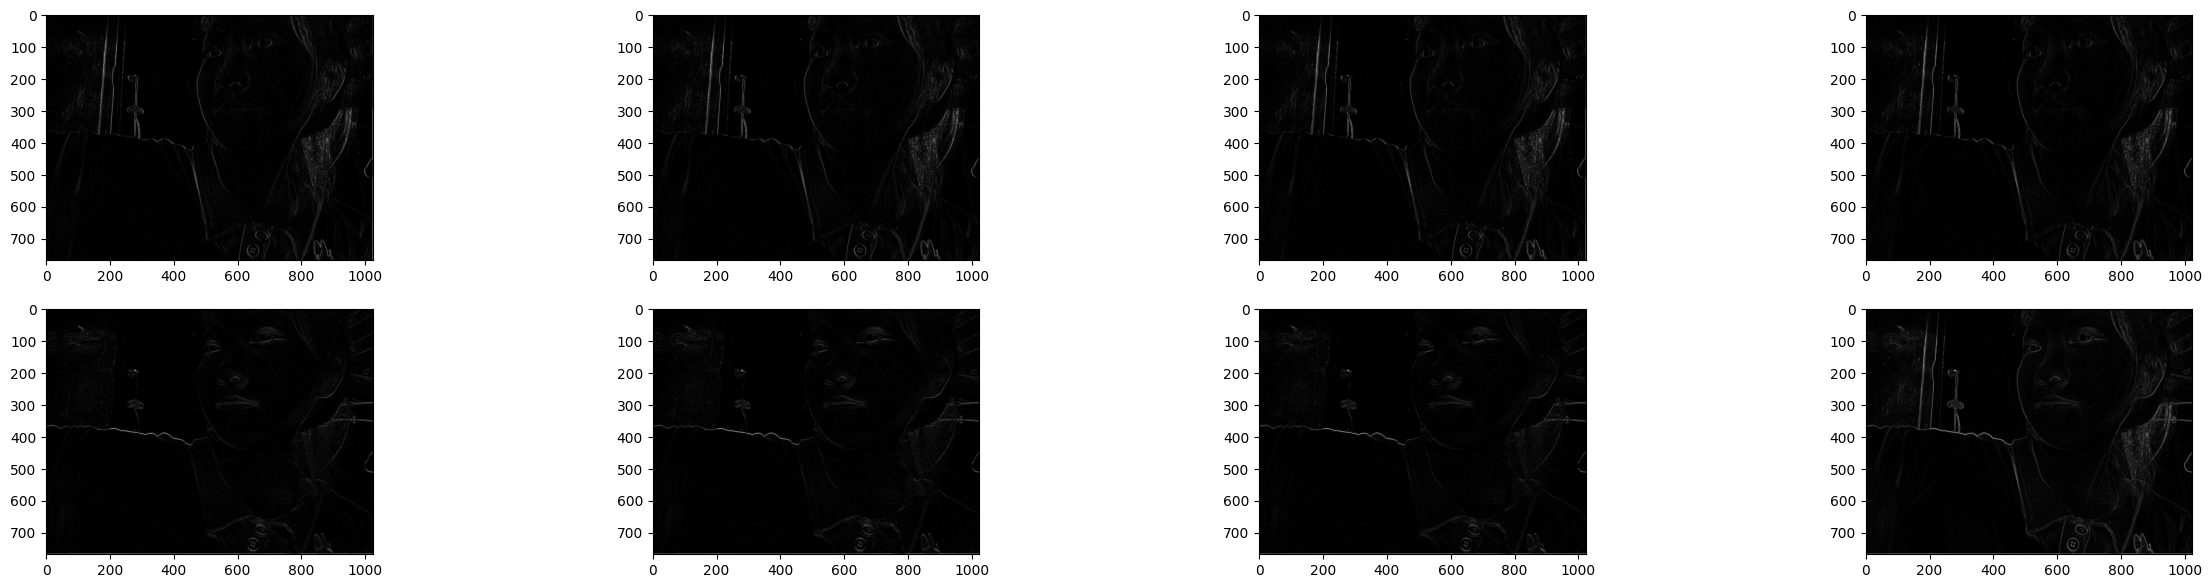

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
robinsonEdges = Robinson(gray)

fig,axes = plt.subplots(2,4,figsize = (30,7),dpi = 100)
rows,cols = axes.shape
for i in range(rows):
    for j in range(cols):
        axes[i,j].imshow(np.abs(robinsonEdges[i*rows +cols]),cmap='gray')

maxImg = getMaxResponse(robinsonEdges)






## 显示局部最大响应

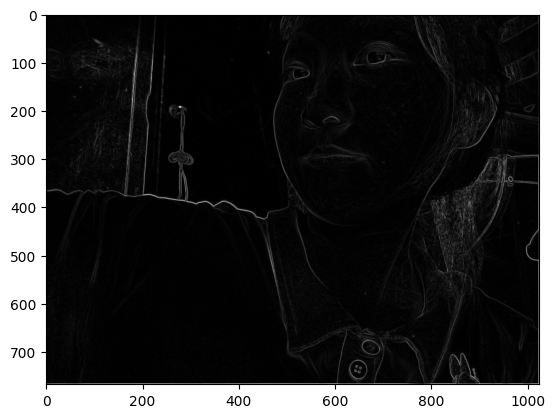

In [62]:
plt.imshow(maxImg,cmap='gray')
plt.show()

### 答题卡测试

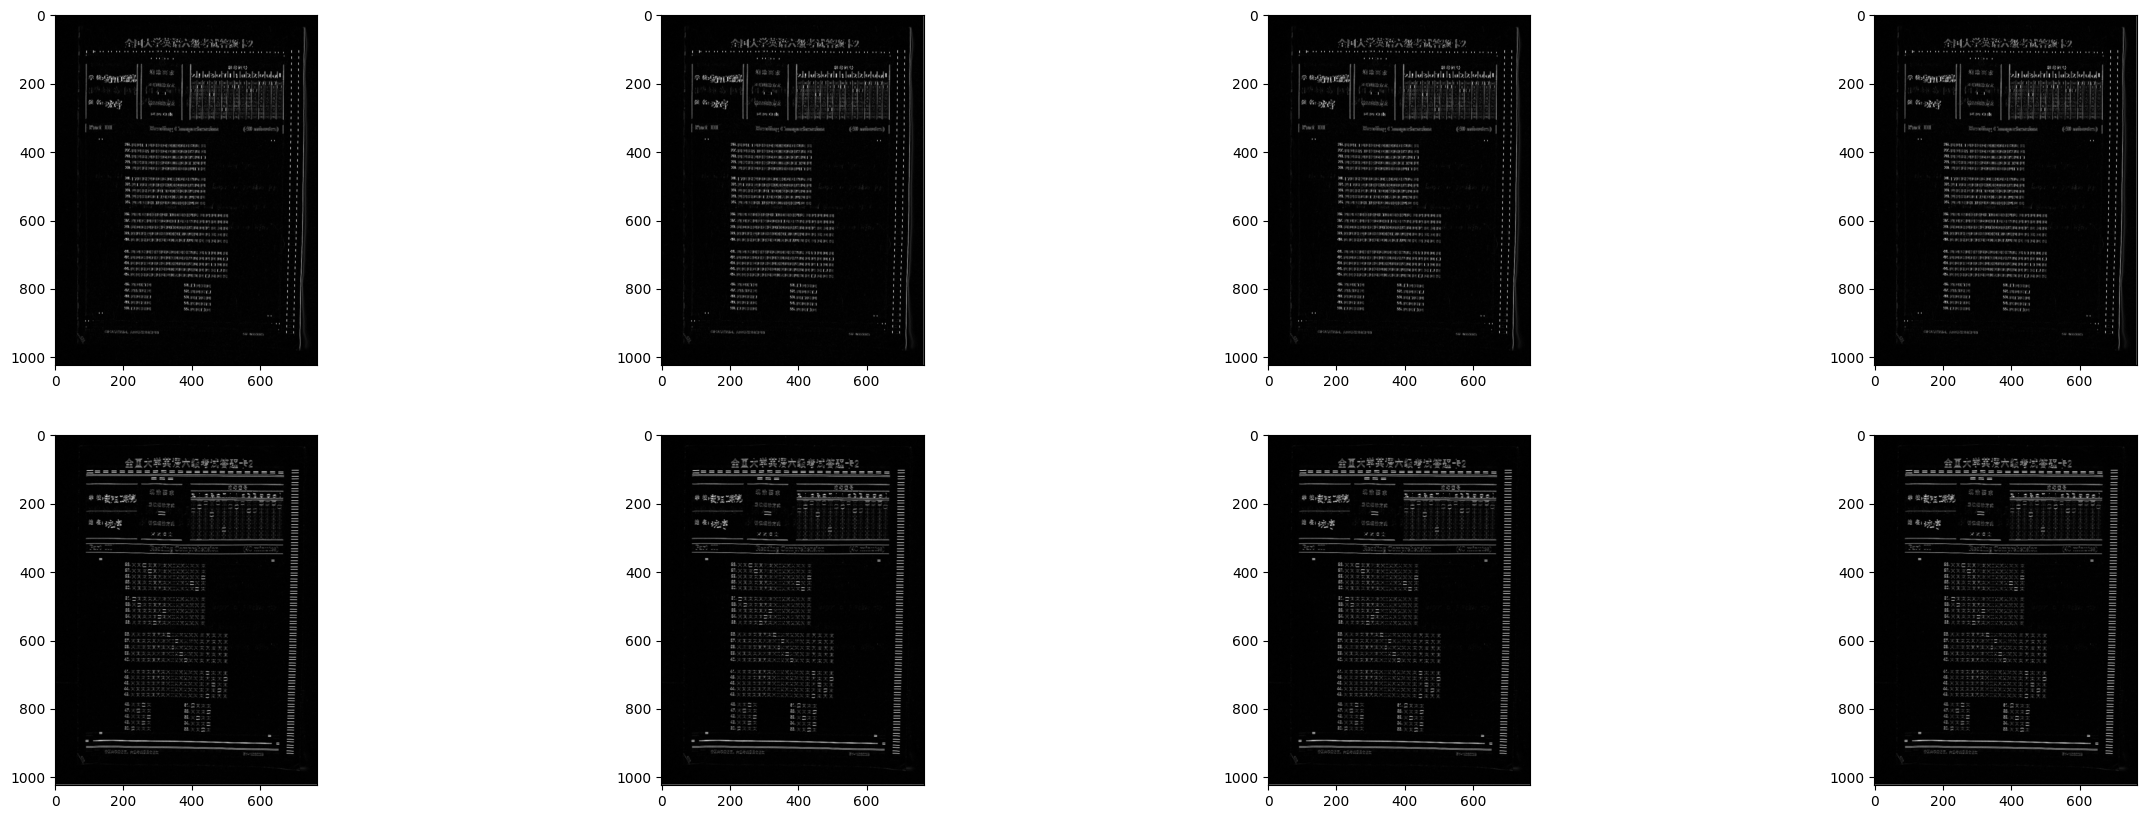

In [68]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 

bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

robinsonEdges = Robinson(gray)
maxImg = getMaxResponse(robinsonEdges)
fig,axes = plt.subplots(2,4,figsize = (30,10),dpi = 100)
rows,cols = axes.shape
for i in range(rows):
    for j in range(cols):
        axes[i,j].imshow(np.abs(robinsonEdges[i*rows +cols]),cmap='gray')


## 显示局部最大响应

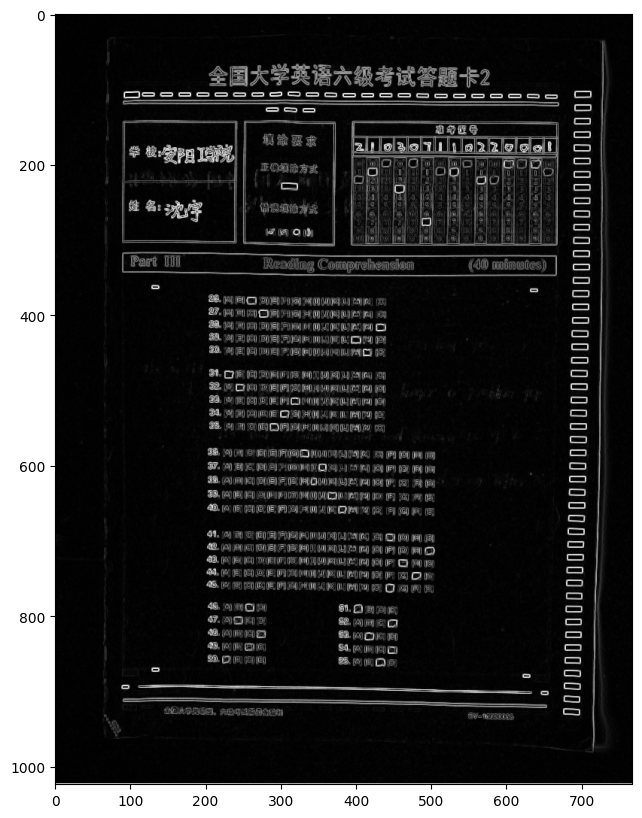

In [71]:
maxImg = getMaxResponse(robinsonEdges)
plt.figure(figsize=(10,10))
plt.imshow(maxImg,cmap='gray')
plt.show()

# example 9-9 Kirsch operator

## define kirsh operator 

In [75]:
import numpy as np 
import cv2 
import matplotlib.pyplot as plt
N = np.array([[5,5,5],[-3,0,-3],[-3,-3,-3]])
S = np.flip(N,axis = 0)
E = np.array([[-3,-3,5],[-3,0,5],[-3,-3,5]])
W = np.flip(E,axis = 1)

NE = np.array([[-3,5,5],[-3,0,5],[-3,-3,-3]])
SW = np.flip(np.flip(NE,axis=0),axis = 1)

NW = np.array([[5,5,-3],[5,0,-3],[-3,-3,-3]])
SE = np.flip(np.flip(NW,axis = 0),axis = 1)
print('N:\n{}'.format(N) )
print('S:\n %s' %(S))
print('E:\n %s'%(E)) 
print('W:\n%s'%W)

print('NE:\n%s'%NE) 
print('SW:\n%s'%SW )

print('NW:\n%s'%NW) 
print('SE:\n%s'%SE) 

N:
[[ 5  5  5]
 [-3  0 -3]
 [-3 -3 -3]]
S:
 [[-3 -3 -3]
 [-3  0 -3]
 [ 5  5  5]]
E:
 [[-3 -3  5]
 [-3  0  5]
 [-3 -3  5]]
W:
[[ 5 -3 -3]
 [ 5  0 -3]
 [ 5 -3 -3]]
NE:
[[-3  5  5]
 [-3  0  5]
 [-3 -3 -3]]
SW:
[[-3 -3 -3]
 [ 5  0 -3]
 [ 5  5 -3]]
NW:
[[ 5  5 -3]
 [ 5  0 -3]
 [-3 -3 -3]]
SE:
[[-3 -3 -3]
 [-3  0  5]
 [-3  5  5]]


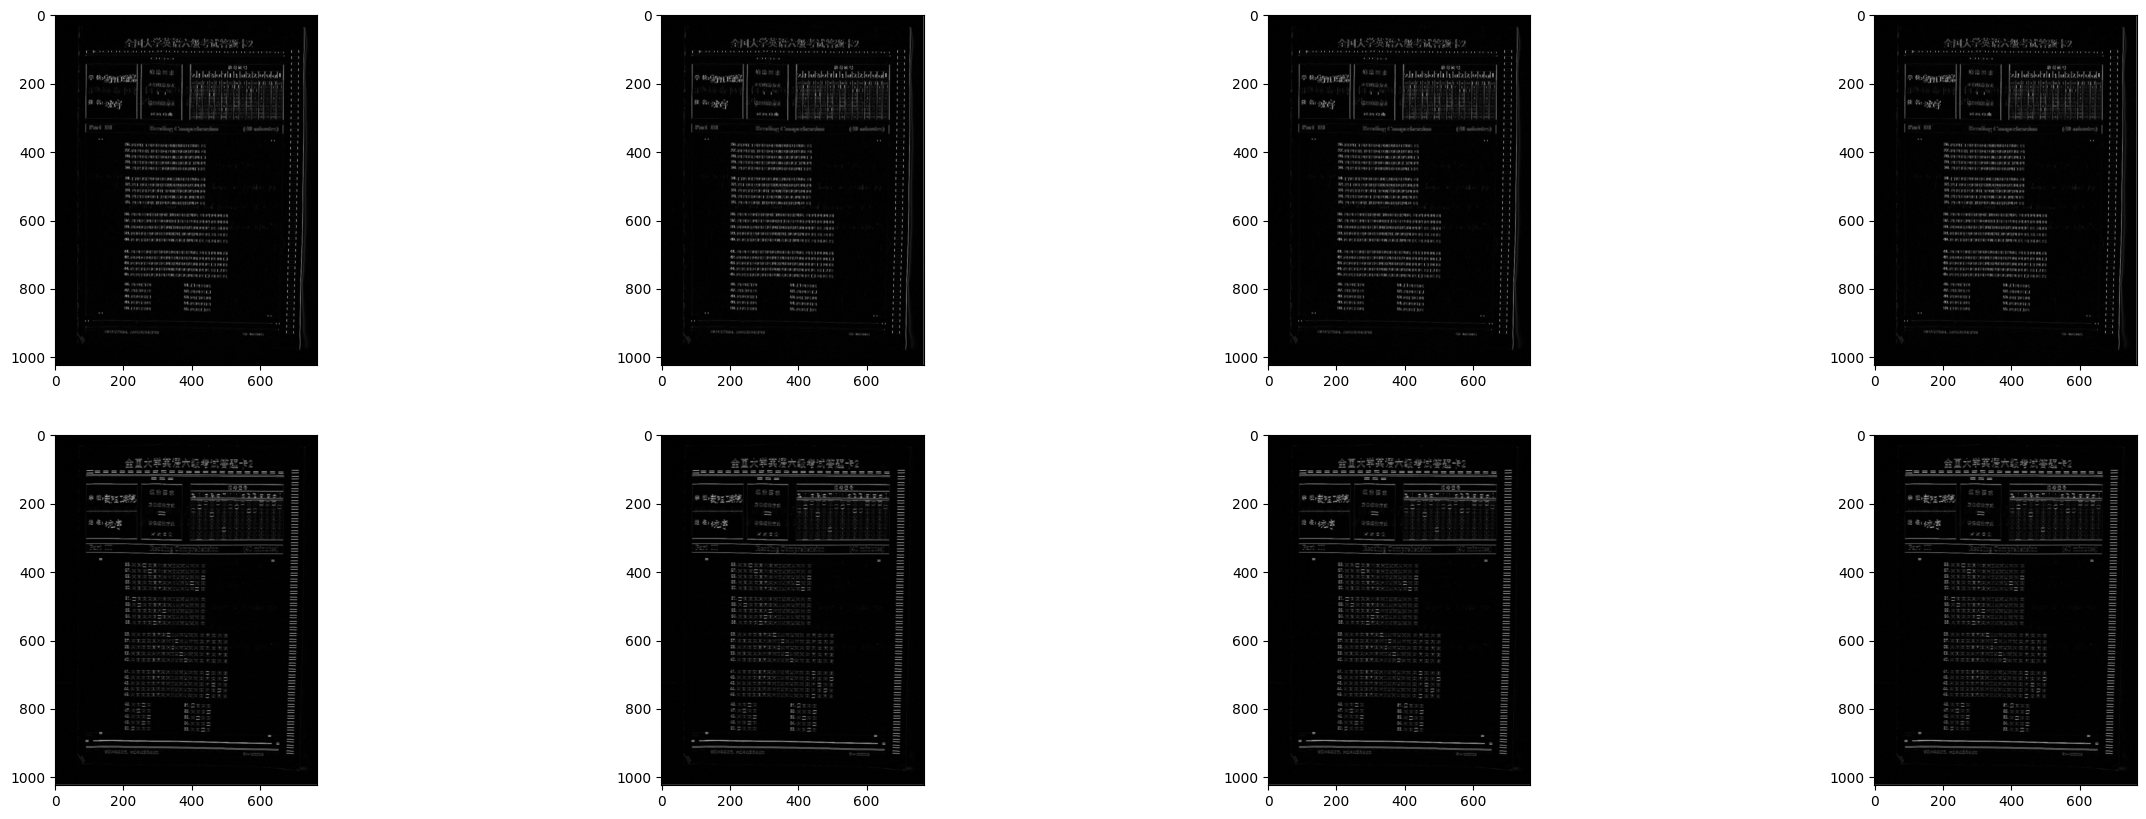

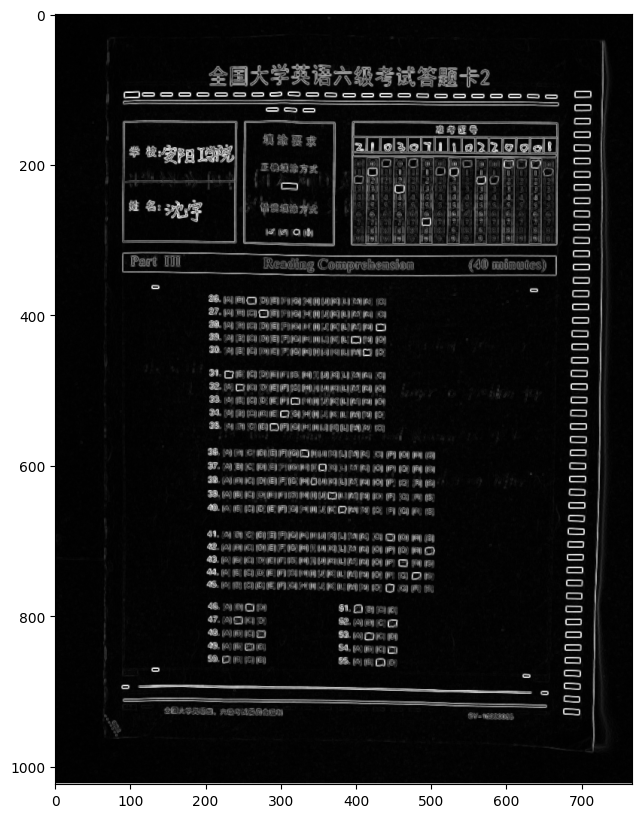

In [80]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 



def convolve(gray,kernel):
    '''
    kernel is odd size
    gray is one channel image 
    '''
    flipKernel = np.flip(np.flip(kernel,axis=0),axis = 1)
    kh,kw = kernel.shape
    padH = kh//2
    padW = kh//2
    H,W = gray.shape
    padGray = np.zeros((H+2*padH,W+2*padW),dtype = np.float64)
    padGray[padH:H + padH,padW:W + padW] = gray
    outGray = np.zeros((H+2*padH,W+2*padW),dtype = np.float64)
    for i  in range(padH,H + padH):
        for j in range(padW,W+padW):
            patch = padGray[i-padH:i+padH+1,j-padW:j+padW+1]
            outGray[i,j] = np.sum(patch*kernel)
    result = outGray[padH:H+padH,padW:W + padW]
    return result.copy()





def Kirsh(gray):
    N = np.array([[5,5,5],[-3,0,-3],[-3,-3,-3]])
    S = np.flip(N,axis = 0)
    E = np.array([[-3,-3,5],[-3,0,5],[-3,-3,5]])
    W = np.flip(E,axis = 1)

    NE = np.array([[-3,5,5],[-3,0,5],[-3,-3,-3]])
    SW = np.flip(np.flip(NE,axis=0),axis = 1)

    NW = np.array([[5,5,-3],[5,0,-3],[-3,-3,-3]])
    SE = np.flip(np.flip(NW,axis = 0),axis = 1)
    kernelList = [E,NE,N,NW,W,SW,S,SE]
    kirshEdges = []
    for i  in range(0,len(kernelList)):
        tmpKernel = kernelList[i]
        tmpKernel = np.flip(tmpKernel,axis=0)
        tmpKernel = np.flip(tmpKernel,axis = 1)
        tmpGray = convolve(gray,tmpKernel)
        kirshEdges.append(tmpGray)
    
    return kirshEdges



def getMaxResponse(kirshEdges):
    H,W = kirshEdges[0].shape

    mergeImg = np.zeros((H,W,len(kirshEdges)))
    for (i,img) in enumerate(kirshEdges):
        mergeImg[:,:,i] = np.abs(img)
    
    maxImg = np.max(mergeImg,axis=2)
    return maxImg


bgr = cv2.imread('/home/aistudio/answer_sheet2_A.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(768,1024))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kirshEdges = Kirsh(gray)
maxImg = getMaxResponse(kirshEdges)
fig,axes = plt.subplots(2,4,figsize = (30,10),dpi = 100)
rows,cols = axes.shape
for i in range(rows):
    for j in range(cols):
        axes[i,j].imshow(np.abs(kirshEdges[i*rows +cols]),cmap='gray')
        

    
maxImg = getMaxResponse(kirshEdges)
plt.figure(figsize=(10,10))
plt.imshow(maxImg,cmap='gray')
plt.show()


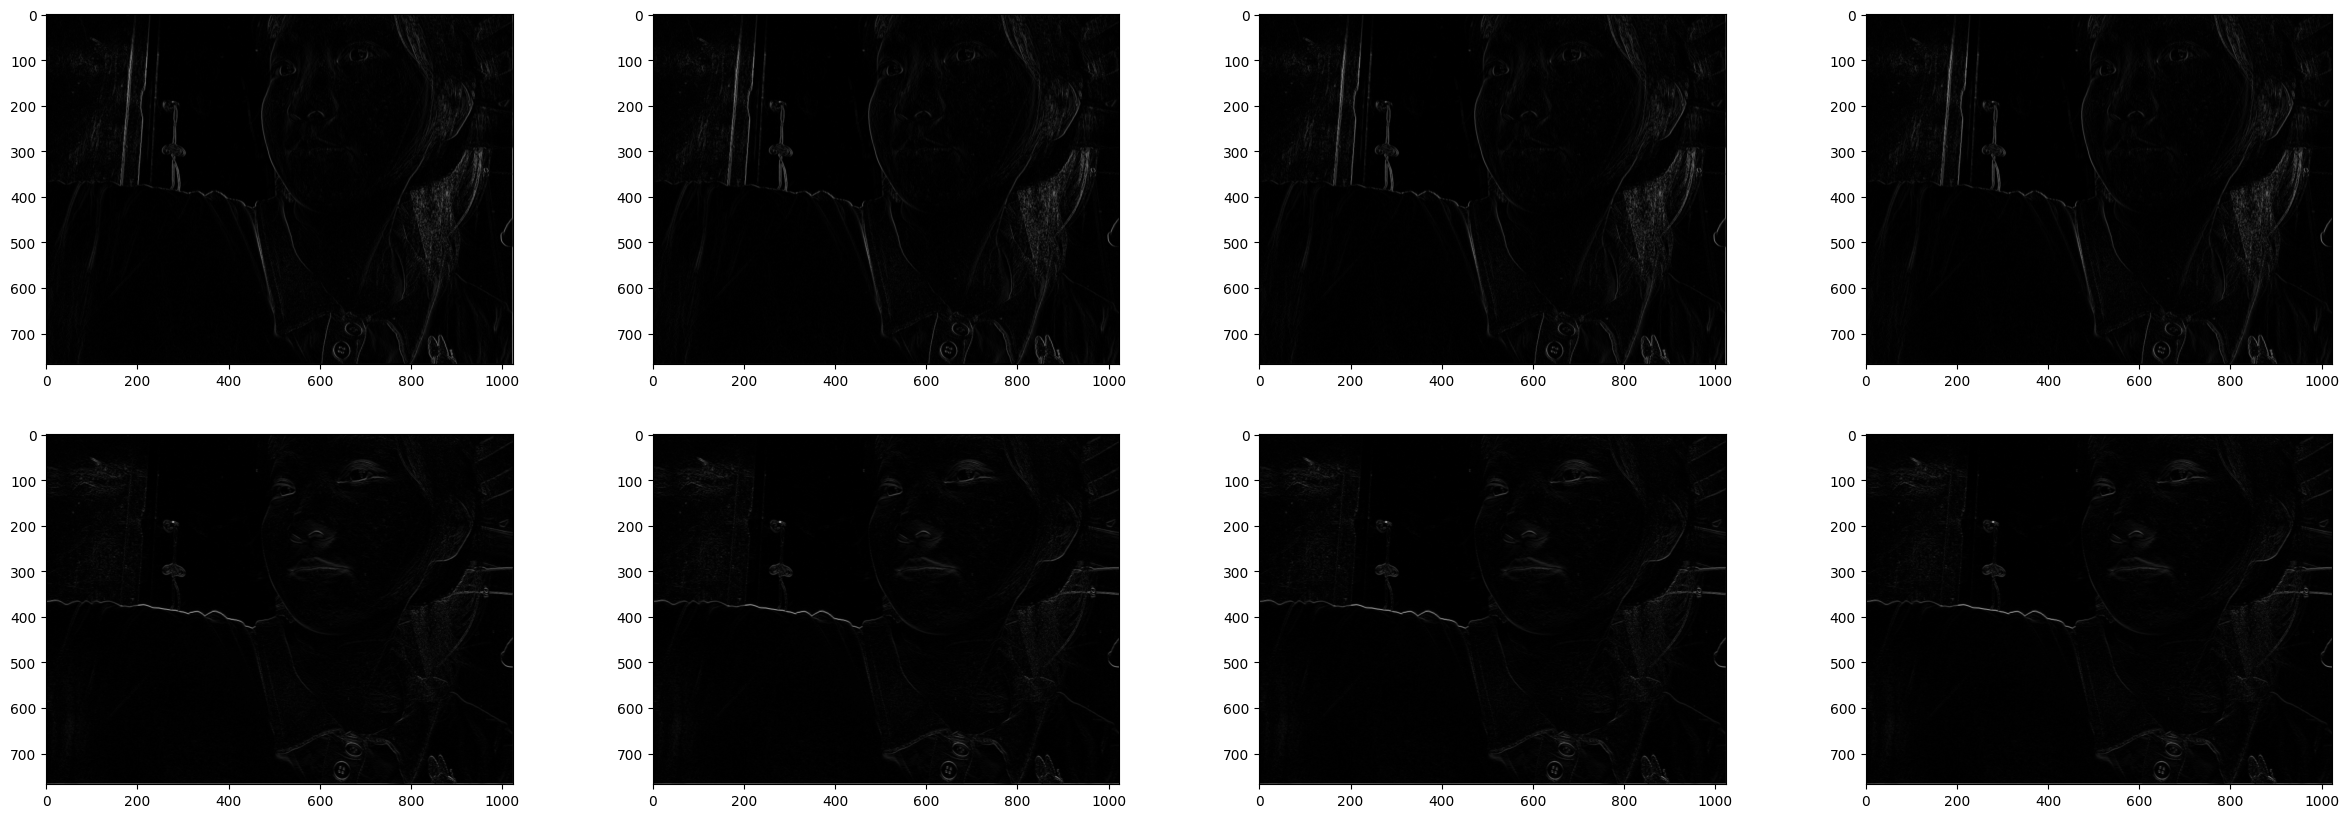

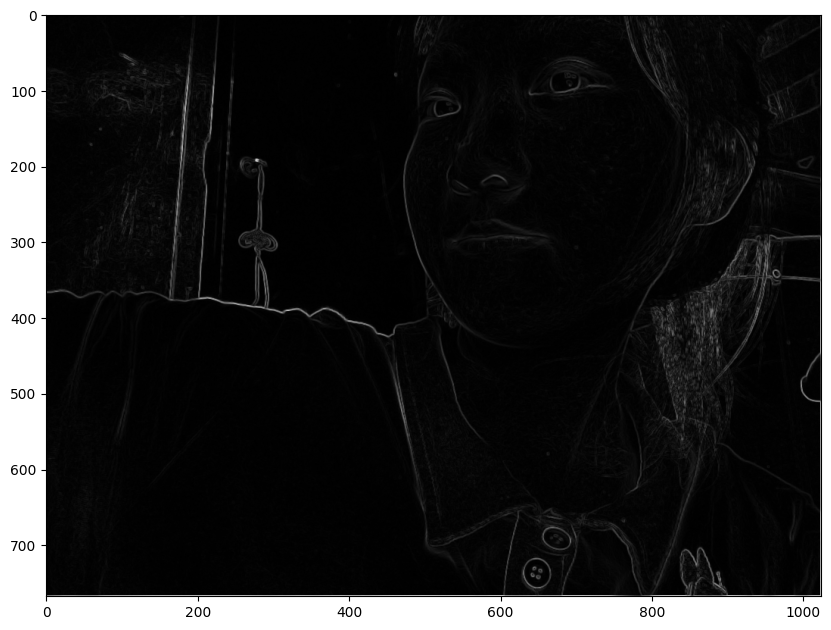

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 



def convolve(gray,kernel):
    '''
    kernel is odd size
    gray is one channel image 
    '''
    flipKernel = np.flip(np.flip(kernel,axis=0),axis = 1)
    kh,kw = kernel.shape
    padH = kh//2
    padW = kh//2
    H,W = gray.shape
    padGray = np.zeros((H+2*padH,W+2*padW),dtype = np.float64)
    padGray[padH:H + padH,padW:W + padW] = gray
    outGray = np.zeros((H+2*padH,W+2*padW),dtype = np.float64)
    for i  in range(padH,H + padH):
        for j in range(padW,W+padW):
            patch = padGray[i-padH:i+padH+1,j-padW:j+padW+1]
            outGray[i,j] = np.sum(patch*kernel)
    result = outGray[padH:H+padH,padW:W + padW]
    return result.copy()





def Kirsh(gray):
    N = np.array([[5,5,5],[-3,0,-3],[-3,-3,-3]])
    S = np.flip(N,axis = 0)
    E = np.array([[-3,-3,5],[-3,0,5],[-3,-3,5]])
    W = np.flip(E,axis = 1)

    NE = np.array([[-3,5,5],[-3,0,5],[-3,-3,-3]])
    SW = np.flip(np.flip(NE,axis=0),axis = 1)

    NW = np.array([[5,5,-3],[5,0,-3],[-3,-3,-3]])
    SE = np.flip(np.flip(NW,axis = 0),axis = 1)
    kernelList = [E,NE,N,NW,W,SW,S,SE]
    kirshEdges = []
    for i  in range(0,len(kernelList)):
        tmpKernel = kernelList[i]
        tmpKernel = np.flip(tmpKernel,axis=0)
        tmpKernel = np.flip(tmpKernel,axis = 1)
        tmpGray = convolve(gray,tmpKernel)
        kirshEdges.append(tmpGray)
    
    return kirshEdges



def getMaxResponse(kirshEdges):
    H,W = kirshEdges[0].shape

    mergeImg = np.zeros((H,W,len(kirshEdges)))
    for (i,img) in enumerate(kirshEdges):
        mergeImg[:,:,i] = np.abs(img)
    
    maxImg = np.max(mergeImg,axis=2)
    return maxImg


bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)

kirshEdges = Kirsh(gray)
maxImg = getMaxResponse(kirshEdges)
fig,axes = plt.subplots(2,4,figsize = (30,10),dpi = 100)
rows,cols = axes.shape
for i in range(rows):
    for j in range(cols):
        axes[i,j].imshow(np.abs(kirshEdges[i*rows +cols]),cmap='gray')
        

    
maxImg = getMaxResponse(kirshEdges)
plt.figure(figsize=(10,10))
plt.imshow(maxImg,cmap='gray')
plt.show()


# Lalacian Operator
![LOG0.jpg](LOG0.jpg)
![LOG1.jpg](LOG1.jpg)
![](LOG3.jpg)

## 一维高斯核

0.3989422804014327
[-10  -9  -8  -7  -6  -5  -4  -3  -2  -1   0   1   2   3   4   5   6   7
   8   9  10]


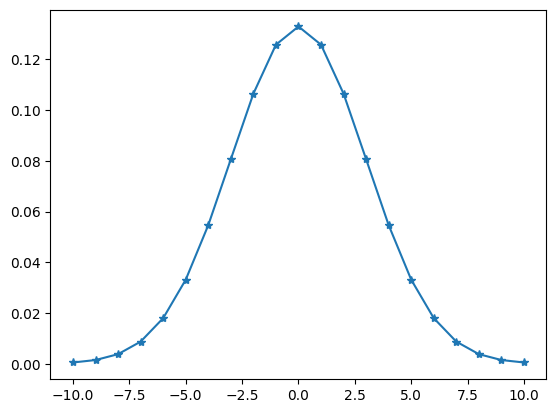

[0.00051409 0.00147728 0.00379866 0.00874063 0.01799699 0.03315905
 0.05467002 0.08065691 0.10648267 0.12579441 0.13298076 0.12579441
 0.10648267 0.08065691 0.05467002 0.03315905 0.01799699 0.00874063
 0.00379866 0.00147728 0.00051409]
0.9995621869619143


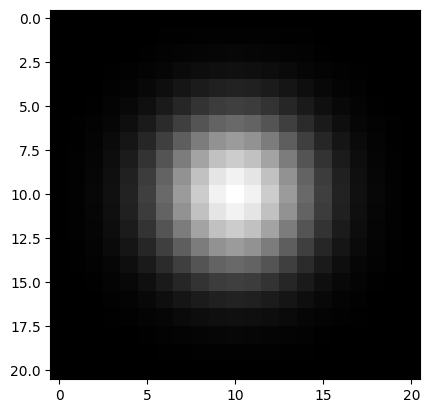

[[0.00051409]
 [0.00147728]
 [0.00379866]
 [0.00874063]
 [0.01799699]
 [0.03315905]
 [0.05467002]
 [0.08065691]
 [0.10648267]
 [0.12579441]
 [0.13298076]
 [0.12579441]
 [0.10648267]
 [0.08065691]
 [0.05467002]
 [0.03315905]
 [0.01799699]
 [0.00874063]
 [0.00379866]
 [0.00147728]
 [0.00051409]]
[[2.64291611e-07 7.59460747e-07 1.95286554e-06 4.49349653e-06
  9.25212596e-06 1.70468335e-05 2.81054770e-05 4.14651518e-05
  5.47419944e-05 6.46700251e-05 6.83644778e-05 6.46700251e-05
  5.47419944e-05 4.14651518e-05 2.81054770e-05 1.70468335e-05
  9.25212596e-06 4.49349653e-06 1.95286554e-06 7.59460747e-07
  2.64291611e-07]
 [7.59460747e-07 2.18236448e-06 5.61169806e-06 1.29123819e-05
  2.65866421e-05 4.89852888e-05 8.07630877e-05 1.19153063e-04
  1.57305015e-04 1.85833918e-04 1.96450190e-04 1.85833918e-04
  1.57305015e-04 1.19153063e-04 8.07630877e-05 4.89852888e-05
  2.65866421e-05 1.29123819e-05 5.61169806e-06 2.18236448e-06
  7.59460747e-07]
 [1.95286554e-06 5.61169806e-06 1.44298331e-05 3.

In [82]:
import numpy as np 
import matplotlib.pyplot as plt
def gaussian(x,sigma, mean=0):
    f = 1/(np.sqrt(2*np.pi)*sigma)*np.exp(-x*x/(2*sigma*sigma))
    return f

f = gaussian(0,1,0)
print(f)

x = np.arange(-10,11,1)
print(x)
g = gaussian(x,sigma = 3,mean = 0)
plt.plot(x,g,marker='*')
plt.show()

print(g)
print(np.sum(g))

g1 = g.reshape(-1,1)
g2d = g1  @ g1.T

plt.imshow(g2d,cmap='gray')
plt.show() 
print(g1)
print(g2d)




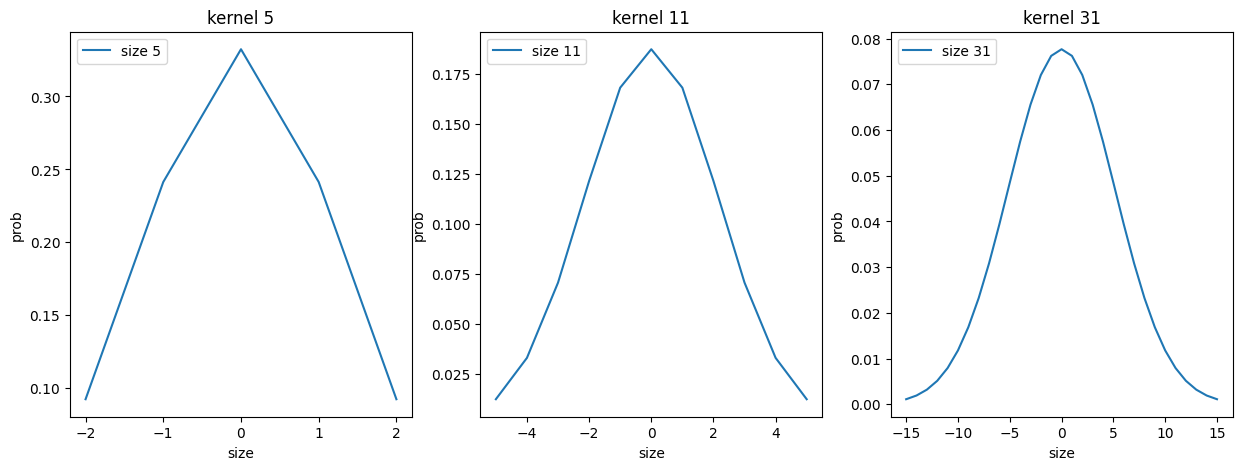

In [83]:
import numpy as np 
import matplotlib.pyplot as plt
ksize = 5
nx = ksize-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel5 = cv2.getGaussianKernel(ksize,sigma,cv2.CV_64F)


ksize = 11
nx = ksize-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel11 = cv2.getGaussianKernel(ksize,sigma,cv2.CV_64F)


ksize = 31
nx = ksize-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel31 = cv2.getGaussianKernel(ksize,sigma,cv2.CV_64F)


fig,ax = plt.subplots(1,3,figsize=(15,5),dpi = 100)
ax0_img = ax[0].plot(np.arange(-2,3),kernel5,label='size 5')
ax1_img = ax[1].plot(np.arange(-5,6),kernel11,label = 'size 11')
ax2_img = ax[2].plot(np.arange(-15,16),kernel31,label='size 31')
ax[0].set_title('kernel 5')
ax[0].set_xlabel('size')
ax[0].set_ylabel('prob')
ax[0].legend(loc='upper left')


ax[1].set_title('kernel 11')
ax[1].set_xlabel('size')
ax[1].set_ylabel('prob')
ax[1].legend(loc='upper left')

ax[2].set_title('kernel 31')
ax[2].set_xlabel('size')
ax[2].set_ylabel('prob')
ax[2].legend(loc='upper left')


## 一维的DoG函数

(7, 1)
(11, 1)
[[0.0404196 ]
 [0.11442248]
 [0.21363035]
 [0.26305515]
 [0.21363035]
 [0.11442248]
 [0.0404196 ]]
[[0.        ]
 [0.        ]
 [0.0404196 ]
 [0.11442248]
 [0.21363035]
 [0.26305515]
 [0.21363035]
 [0.11442248]
 [0.0404196 ]
 [0.        ]
 [0.        ]]


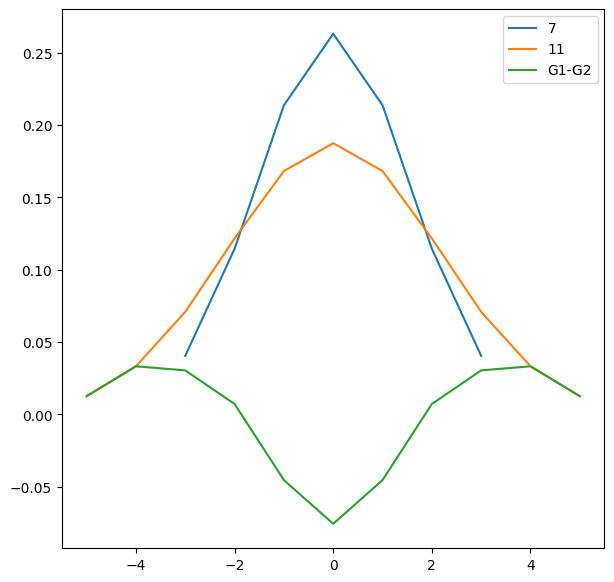

In [17]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2
ksize2 = 7
nx = ksize2-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel7 = cv2.getGaussianKernel(ksize2,sigma,cv2.CV_64F)
print(kernel7.shape)

ksize1 = 11
nx = ksize1-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel11 = cv2.getGaussianKernel(ksize1,sigma,cv2.CV_64F)

G1 = kernel11
G2 = np.zeros(G1.shape)
print(G1.shape)
padx = (ksize1-ksize2)//2
G2[padx:padx+ksize2,0] =kernel7[:,0] 
print(kernel7)
print(G2)


fig,ax = plt.subplots(1,1,figsize=(7,7),dpi = 100)
ax.plot(np.arange(-3,4),kernel7,label='7')
ax.plot(np.arange(-5,6),kernel11,label='11')
ax.plot(np.arange(-5,6),G1-G2,label ='G1-G2')
#ax.plot(np.arnage(-5,6)))
ax.legend()

(11, 1)
(19, 1)
[[0.01254189]
 [0.03320079]
 [0.07079156]
 [0.12158003]
 [0.16818632]
 [0.18739881]
 [0.16818632]
 [0.12158003]
 [0.07079156]
 [0.03320079]
 [0.01254189]]
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.01254189]
 [0.03320079]
 [0.07079156]
 [0.12158003]
 [0.16818632]
 [0.18739881]
 [0.16818632]
 [0.12158003]
 [0.07079156]
 [0.03320079]
 [0.01254189]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]


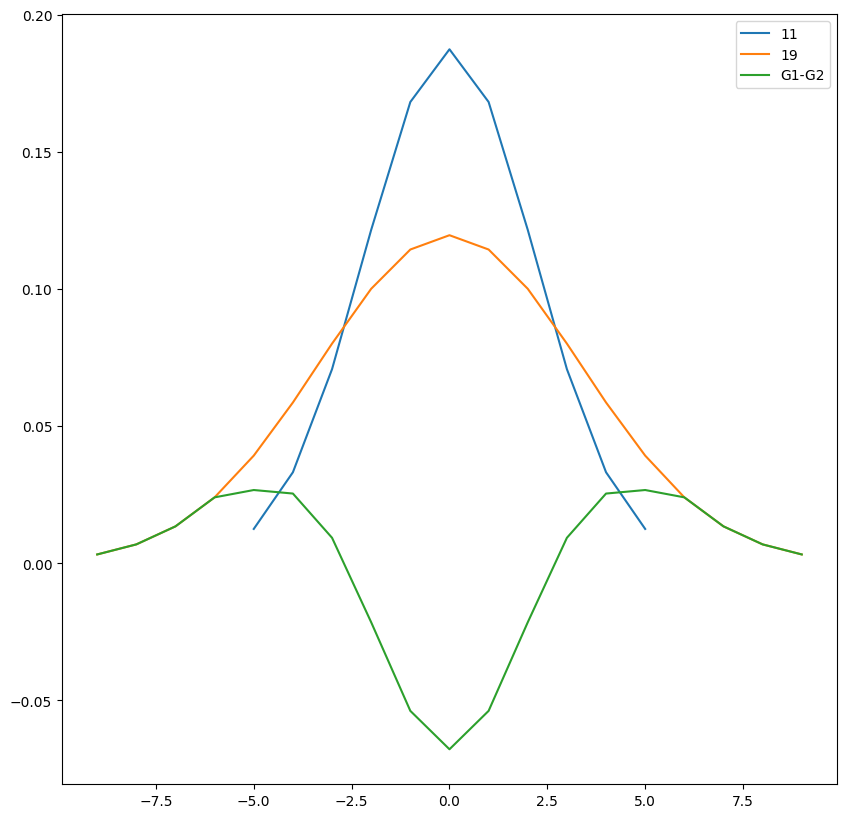

In [18]:
import numpy as np 
import matplotlib.pyplot as plt
ksize2 = 11
nx = ksize2-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel7 = cv2.getGaussianKernel(ksize2,sigma,cv2.CV_64F)
print(kernel7.shape)

ksize1 = 19
nx = ksize1-1
sigma = (nx-1)/2.0*0.3 + 0.8
kernel11 = cv2.getGaussianKernel(ksize1,sigma,cv2.CV_64F)

G1 = kernel11
G2 = np.zeros(G1.shape)
print(G1.shape)
padx = (ksize1-ksize2)//2
G2[padx:padx+ksize2,0] =kernel7[:,0] 
print(kernel7)
print(G2)


fig,ax = plt.subplots(1,1,figsize=(10,10),dpi = 100)
ax.plot(np.arange(-(ksize2//2),ksize2//2+1),kernel7,label='11')
ax.plot(np.arange(-(ksize1//2),ksize1//2+1),kernel11,label='19')
ax.plot(np.arange(-(ksize1//2),ksize1//2+1),G1-G2,label ='G1-G2')
#ax.plot(np.arnage(-5,6)))
ax.legend()

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


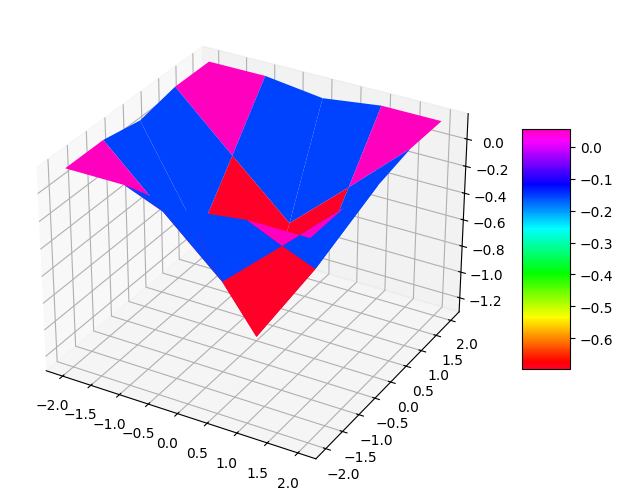

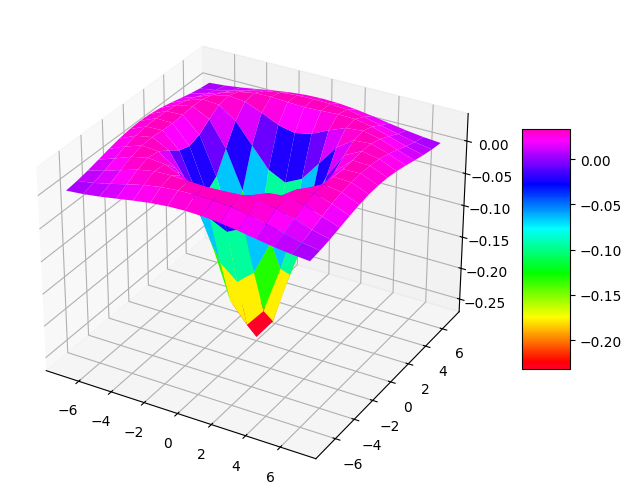

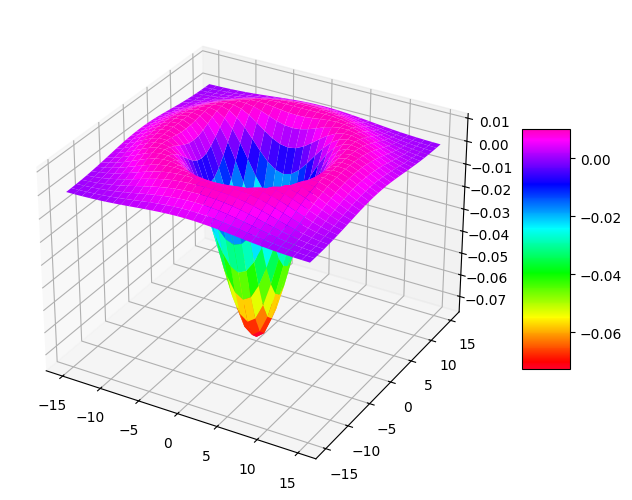

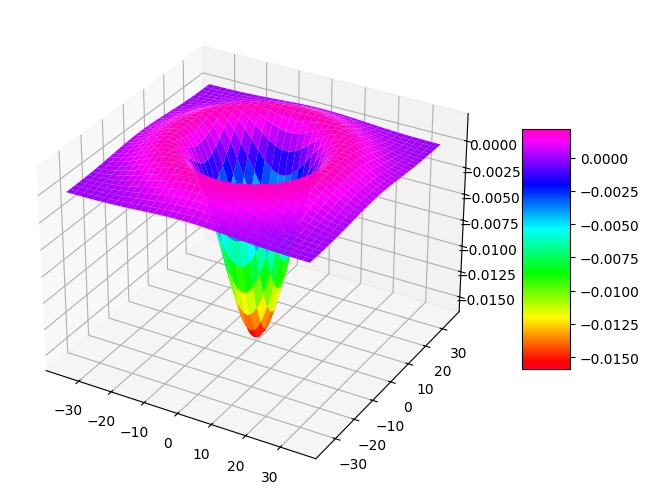

[[ 0.08 -0.57  0.08]
 [-0.57 -2.22 -0.57]
 [ 0.08 -0.57  0.08]]
[[ 0.15  0.16  0.1   0.16  0.15]
 [ 0.16 -0.24 -0.63 -0.24  0.16]
 [ 0.1  -0.63 -1.28 -0.63  0.1 ]
 [ 0.16 -0.24 -0.63 -0.24  0.16]
 [ 0.15  0.16  0.1   0.16  0.15]]
[[ 0.01  0.02  0.03  0.04  0.05  0.05  0.05  0.04  0.03  0.02  0.01]
 [ 0.02  0.03  0.05  0.06  0.06  0.06  0.06  0.06  0.05  0.03  0.02]
 [ 0.03  0.05  0.06  0.04  0.01 -0.    0.01  0.04  0.06  0.05  0.03]
 [ 0.04  0.06  0.04 -0.02 -0.12 -0.16 -0.12 -0.02  0.04  0.06  0.04]
 [ 0.05  0.06  0.01 -0.12 -0.27 -0.35 -0.27 -0.12  0.01  0.06  0.05]
 [ 0.05  0.06 -0.   -0.16 -0.35 -0.43 -0.35 -0.16 -0.    0.06  0.05]
 [ 0.05  0.06  0.01 -0.12 -0.27 -0.35 -0.27 -0.12  0.01  0.06  0.05]
 [ 0.04  0.06  0.04 -0.02 -0.12 -0.16 -0.12 -0.02  0.04  0.06  0.04]
 [ 0.03  0.05  0.06  0.04  0.01 -0.    0.01  0.04  0.06  0.05  0.03]
 [ 0.02  0.03  0.05  0.06  0.06  0.06  0.06  0.06  0.05  0.03  0.02]
 [ 0.01  0.02  0.03  0.04  0.05  0.05  0.05  0.04  0.03  0.02  0.01]]
[[0. 0. 0.

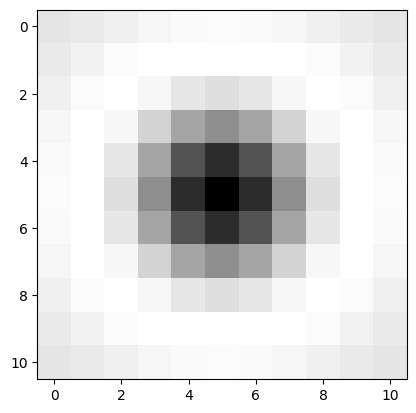

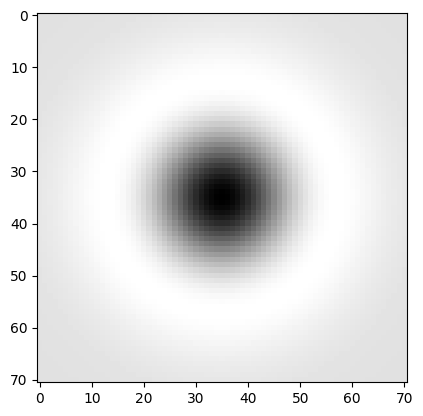

In [153]:
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm


def f_log(x,y,sigma):
    result = ((x*x + y*y -2*sigma*sigma)/(sigma*sigma*sigma*sigma)) * np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return result

def LoG(ksize=3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3 + 0.8
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    result = np.zeros((ksize,ksize),dtype = np.float64)
    for i in x:
        for j in y:
            #print(i,j)
            result[i+d,j+d] = f_log(i,j,sigma)    
    return result

def plotLoG(ksize = 3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3 + 0.8
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    xx,yy = np.meshgrid(x,y)
    zz = LoG(ksize)
    fig = plt.figure()
    ax = Axes3D(fig) # 在窗口上添加3D坐标轴
    fig.add_axes(ax)#使用 ax = Axes3D(fig) ，将自身添加到图像中
    surf = ax.plot_surface(xx,yy,zz,cmap=cm.gist_rainbow)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()


print(np.around(LoG(71)))
plotLoG(5)
plotLoG(15)
plotLoG(31)
plotLoG(71)

print(np.around(LoG(3),decimals=2))
print(np.around(LoG(5),decimals=2))
print(np.around(LoG(11),decimals=2))
print(np.around(LoG(71),decimals=2))
plt.imshow(LoG(11),cmap='gray')
plt.show()


plt.imshow(LoG(71),cmap='gray')
plt.show()






## sigma = (nx-1)/2*0.3+0.8 
## sigma = sigma /2

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


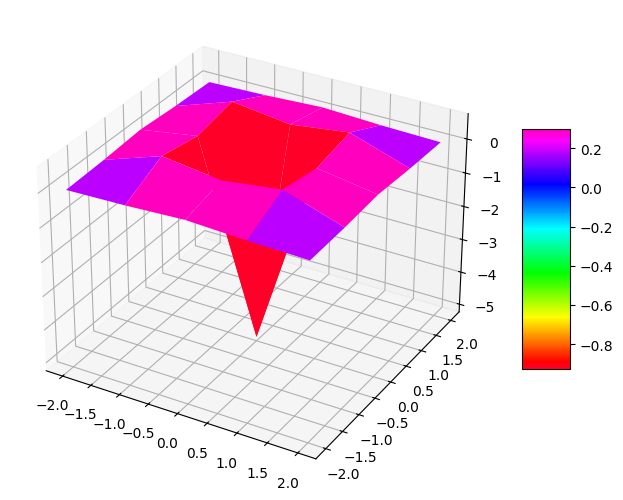

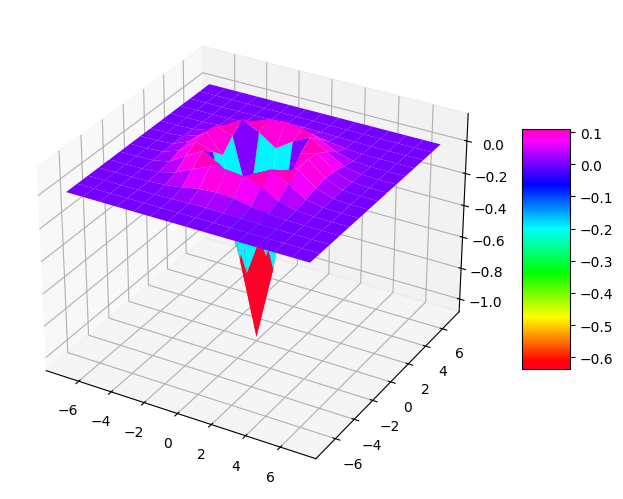

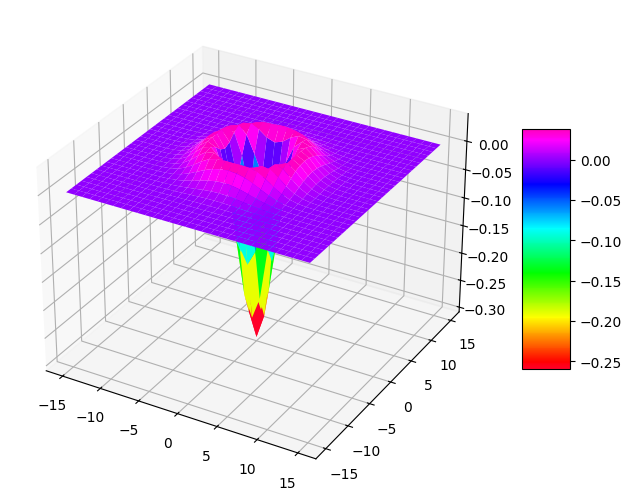

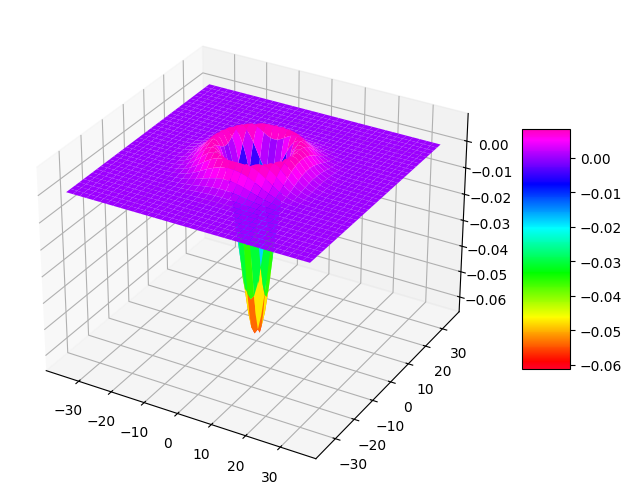

[[ 0.36  1.18  0.36]
 [ 1.18 -8.86  1.18]
 [ 0.36  1.18  0.36]]
[[ 0.    0.05  0.13  0.05  0.  ]
 [ 0.05  0.62  0.4   0.62  0.05]
 [ 0.13  0.4  -5.12  0.4   0.13]
 [ 0.05  0.62  0.4   0.62  0.05]
 [ 0.    0.05  0.13  0.05  0.  ]]
[[ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.01  0.01  0.01  0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.03  0.08  0.1   0.08  0.03  0.    0.    0.  ]
 [ 0.    0.    0.03  0.13  0.23  0.22  0.23  0.13  0.03  0.    0.  ]
 [ 0.    0.01  0.08  0.23 -0.1  -0.64 -0.1   0.23  0.08  0.01  0.  ]
 [ 0.    0.01  0.1   0.22 -0.64 -1.73 -0.64  0.22  0.1   0.01  0.  ]
 [ 0.    0.01  0.08  0.23 -0.1  -0.64 -0.1   0.23  0.08  0.01  0.  ]
 [ 0.    0.    0.03  0.13  0.23  0.22  0.23  0.13  0.03  0.    0.  ]
 [ 0.    0.    0.    0.03  0.08  0.1   0.08  0.03  0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.01  0.01  0.01  0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]
[[0. 0. 0.

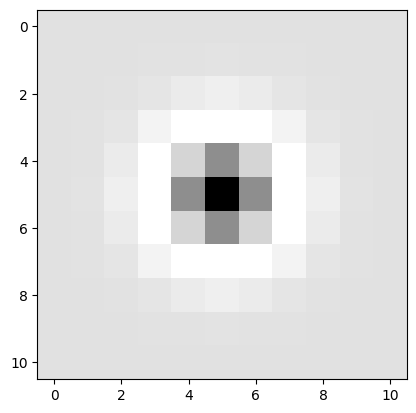

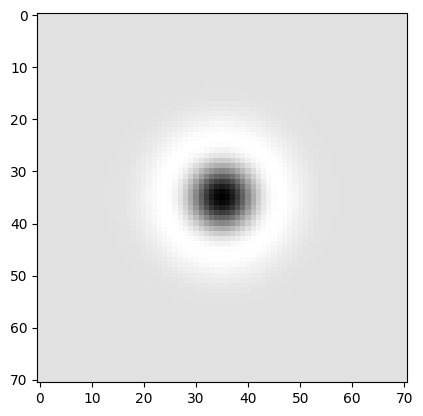

In [154]:
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm


def f_log(x,y,sigma):
    result = ((x*x + y*y -2*sigma*sigma)/(sigma*sigma*sigma*sigma)) * np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return result

def LoG(ksize=3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3+ 0.8
    sigma = sigma*0.5
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    result = np.zeros((ksize,ksize),dtype = np.float64)
    for i in x:
        for j in y:
            #print(i,j)
            result[i+d,j+d] = f_log(i,j,sigma)    
    return result

def plotLoG(ksize = 3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3 + 0.8
    sigma = sigma*0.5
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    xx,yy = np.meshgrid(x,y)
    zz = LoG(ksize)
    fig = plt.figure()
    ax = Axes3D(fig) # 在窗口上添加3D坐标轴
    fig.add_axes(ax)#使用 ax = Axes3D(fig) ，将自身添加到图像中
    surf = ax.plot_surface(xx,yy,zz,cmap=cm.gist_rainbow)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()


print(np.around(LoG(71)))
plotLoG(5)
plotLoG(15)
plotLoG(31)
plotLoG(71)

print(np.around(LoG(3),decimals=2))
print(np.around(LoG(5),decimals=2))
print(np.around(LoG(11),decimals=2))
print(np.around(LoG(71),decimals=2))
plt.imshow(LoG(11),cmap='gray')
plt.show()


plt.imshow(LoG(71),cmap='gray')
plt.show()






## sigma = ksize /6

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


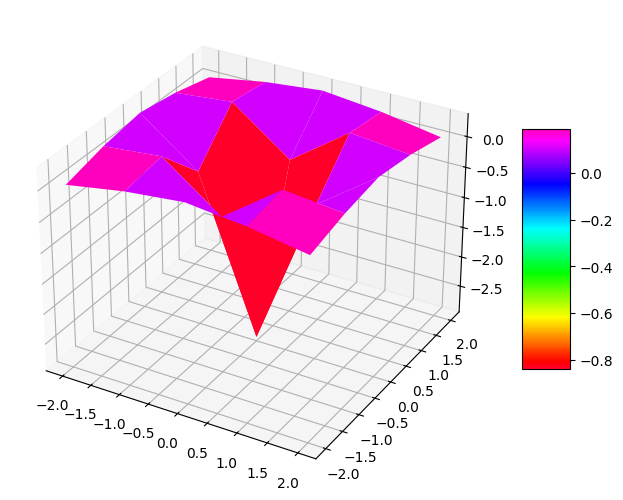

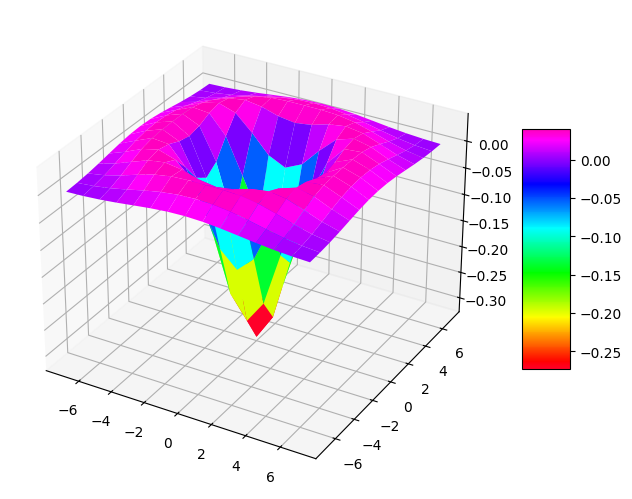

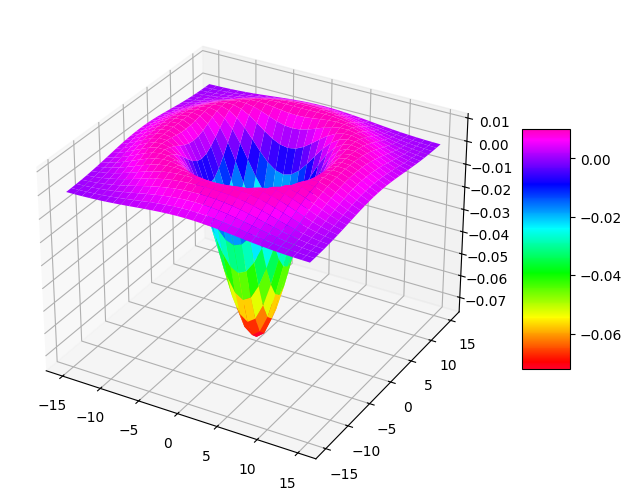

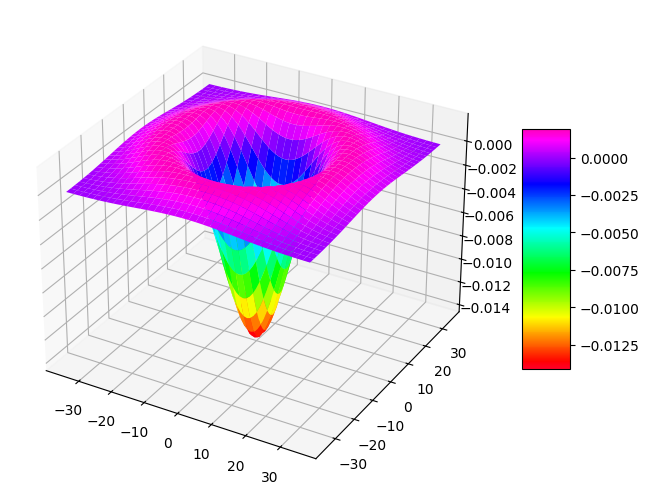

[[ 0.44  1.08  0.44]
 [ 1.08 -8.    1.08]
 [ 0.44  1.08  0.44]]
[[ 0.04  0.2   0.3   0.2   0.04]
 [ 0.2   0.3  -0.39  0.3   0.2 ]
 [ 0.3  -0.39 -2.88 -0.39  0.3 ]
 [ 0.2   0.3  -0.39  0.3   0.2 ]
 [ 0.04  0.2   0.3   0.2   0.04]]
[[ 0.    0.01  0.02  0.03  0.04  0.04  0.04  0.03  0.02  0.01  0.  ]
 [ 0.01  0.02  0.04  0.06  0.07  0.08  0.07  0.06  0.04  0.02  0.01]
 [ 0.02  0.04  0.07  0.08  0.07  0.05  0.07  0.08  0.07  0.04  0.02]
 [ 0.03  0.06  0.08  0.03 -0.07 -0.13 -0.07  0.03  0.08  0.06  0.03]
 [ 0.04  0.07  0.07 -0.07 -0.31 -0.44 -0.31 -0.07  0.07  0.07  0.04]
 [ 0.04  0.08  0.05 -0.13 -0.44 -0.6  -0.44 -0.13  0.05  0.08  0.04]
 [ 0.04  0.07  0.07 -0.07 -0.31 -0.44 -0.31 -0.07  0.07  0.07  0.04]
 [ 0.03  0.06  0.08  0.03 -0.07 -0.13 -0.07  0.03  0.08  0.06  0.03]
 [ 0.02  0.04  0.07  0.08  0.07  0.05  0.07  0.08  0.07  0.04  0.02]
 [ 0.01  0.02  0.04  0.06  0.07  0.08  0.07  0.06  0.04  0.02  0.01]
 [ 0.    0.01  0.02  0.03  0.04  0.04  0.04  0.03  0.02  0.01  0.  ]]
[[0. 0. 0.

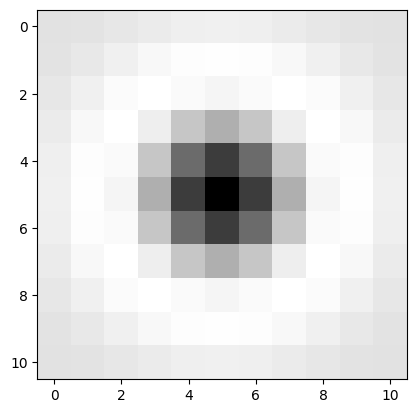

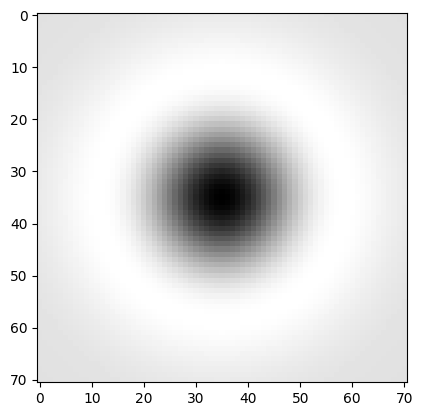

In [161]:
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm


def f_log(x,y,sigma):
    result = ((x*x + y*y -2*sigma*sigma)/(sigma*sigma*sigma*sigma)) * np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return result

def LoG(ksize=3):
    '''
      ksize must be odd
    '''
    nx = ksize -1 
    sigma=ksize/6
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    result = np.zeros((ksize,ksize),dtype = np.float64)
    for i in x:
        for j in y:
            #print(i,j)
            result[i+d,j+d] = f_log(i,j,sigma)    
    return result

def plotLoG(ksize = 3):
    nx = ksize -1 
    sigma=ksize/6
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    xx,yy = np.meshgrid(x,y)
    zz = LoG(ksize)
    fig = plt.figure()
    ax = Axes3D(fig) # 在窗口上添加3D坐标轴
    fig.add_axes(ax)#使用 ax = Axes3D(fig) ，将自身添加到图像中
    surf = ax.plot_surface(xx,yy,zz,cmap=cm.gist_rainbow)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()


print(np.around(LoG(71)))
plotLoG(5)
plotLoG(15)
plotLoG(31)
plotLoG(71)

print(np.around(LoG(3),decimals=2))
print(np.around(LoG(5),decimals=2))
print(np.around(LoG(11),decimals=2))
print(np.around(LoG(71),decimals=2))
plt.imshow(LoG(11),cmap='gray')
plt.show()


plt.imshow(LoG(71),cmap='gray')
plt.show()






## sigma = ksize/9

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


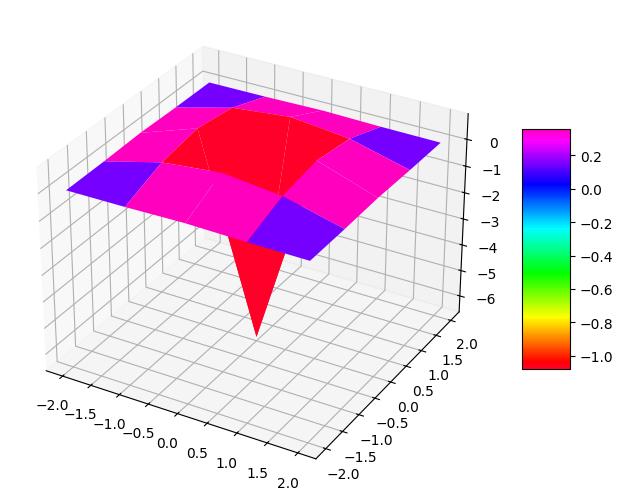

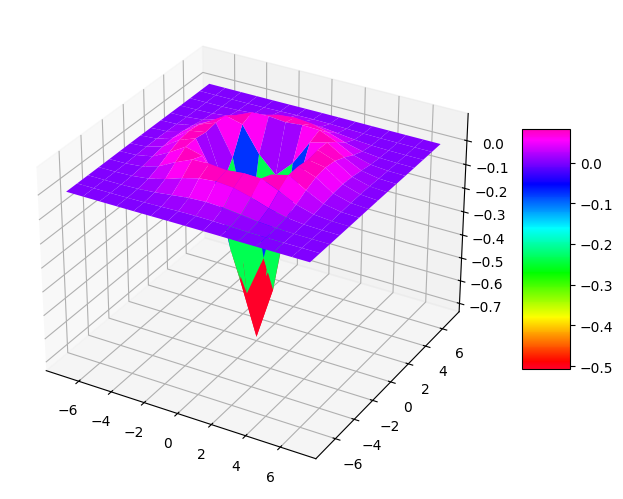

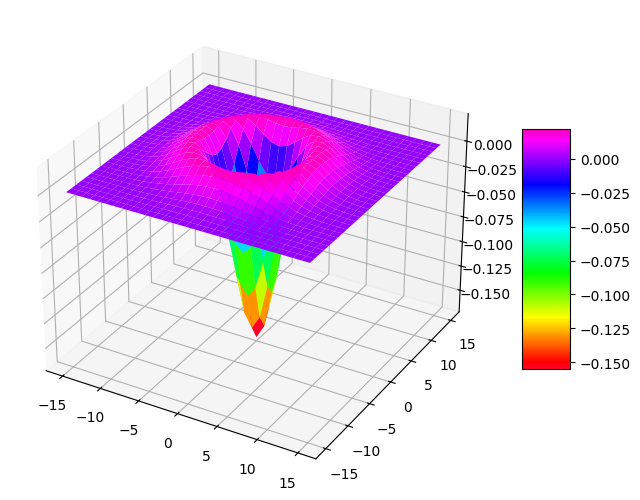

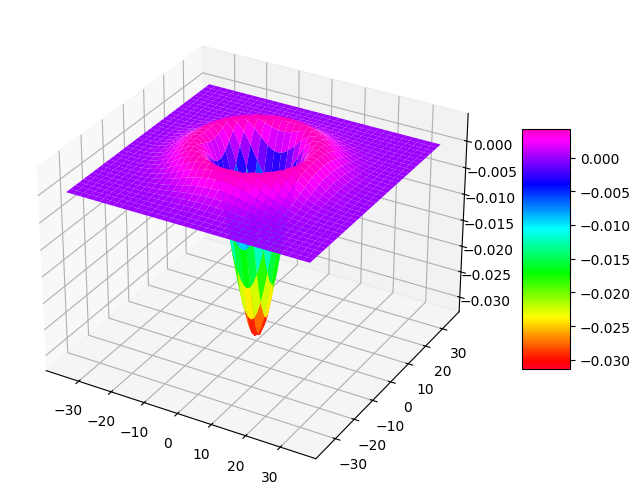

[[  0.02   0.7    0.02]
 [  0.7  -18.     0.7 ]
 [  0.02   0.7    0.02]]
[[ 0.    0.01  0.05  0.01  0.  ]
 [ 0.01  0.57  0.8   0.57  0.01]
 [ 0.05  0.8  -6.48  0.8   0.05]
 [ 0.01  0.57  0.8   0.57  0.01]
 [ 0.    0.01  0.05  0.01  0.  ]]
[[ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.01  0.02  0.03  0.02  0.01  0.    0.    0.  ]
 [ 0.    0.    0.02  0.06  0.11  0.13  0.11  0.06  0.02  0.    0.  ]
 [ 0.    0.01  0.06  0.15  0.17  0.12  0.17  0.15  0.06  0.01  0.  ]
 [ 0.    0.02  0.11  0.17 -0.23 -0.64 -0.23  0.17  0.11  0.02  0.  ]
 [ 0.    0.03  0.13  0.12 -0.64 -1.34 -0.64  0.12  0.13  0.03  0.  ]
 [ 0.    0.02  0.11  0.17 -0.23 -0.64 -0.23  0.17  0.11  0.02  0.  ]
 [ 0.    0.01  0.06  0.15  0.17  0.12  0.17  0.15  0.06  0.01  0.  ]
 [ 0.    0.    0.02  0.06  0.11  0.13  0.11  0.06  0.02  0.    0.  ]
 [ 0.    0.    0.    0.01  0.02  0.03  0.02  0.01  0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]
[

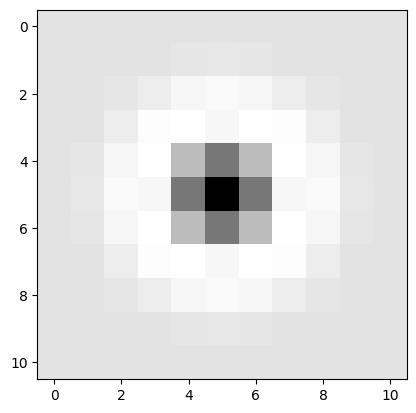

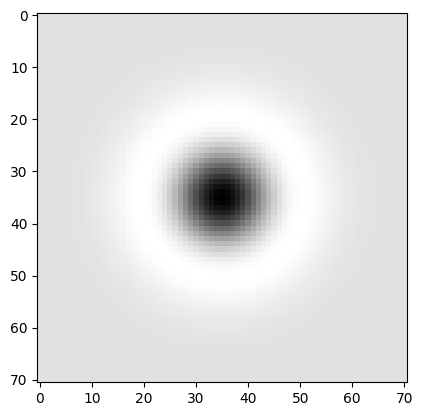

In [6]:
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm


def f_log(x,y,sigma):
    result = ((x*x + y*y -2*sigma*sigma)/(sigma*sigma*sigma*sigma)) * np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return result

def LoG(ksize=3):
    '''
      ksize must be odd
    '''
    nx = ksize -1 
    sigma=ksize/9
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    result = np.zeros((ksize,ksize),dtype = np.float64)
    for i in x:
        for j in y:
            #print(i,j)
            result[i+d,j+d] = f_log(i,j,sigma)    
    return result

def plotLoG(ksize = 3):
    nx = ksize -1 
    sigma=ksize/6
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    xx,yy = np.meshgrid(x,y)
    zz = LoG(ksize)
    fig = plt.figure()
    ax = Axes3D(fig) # 在窗口上添加3D坐标轴
    fig.add_axes(ax)#使用 ax = Axes3D(fig) ，将自身添加到图像中
    surf = ax.plot_surface(xx,yy,zz,cmap=cm.gist_rainbow)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()


print(np.around(LoG(71)))
plotLoG(5)
plotLoG(15)
plotLoG(31)
plotLoG(71)

print(np.around(LoG(3),decimals=2))
print(np.around(LoG(5),decimals=2))
print(np.around(LoG(11),decimals=2))
print(np.around(LoG(71),decimals=2))
plt.imshow(LoG(11),cmap='gray')
plt.show()


plt.imshow(LoG(71),cmap='gray')
plt.show()






In [15]:
a = np.array([[ 0. ,  0.01,  0.05 , 0.01,  0.  ], [ 0.01 , 0.57,  0.8,   0.57,  0.01], [ 0.05 , 0.8 , -6.48,  0.8 ,  0.05], [ 0.01 , 0.57 , 0.8,   0.57,  0.01],[ 0. ,   0.01 , 0.05,  0.01,  0.  ]])

print(a)
b = a/0.4
print(b)

[[ 0.    0.01  0.05  0.01  0.  ]
 [ 0.01  0.57  0.8   0.57  0.01]
 [ 0.05  0.8  -6.48  0.8   0.05]
 [ 0.01  0.57  0.8   0.57  0.01]
 [ 0.    0.01  0.05  0.01  0.  ]]
[[  0.      0.025   0.125   0.025   0.   ]
 [  0.025   1.425   2.      1.425   0.025]
 [  0.125   2.    -16.2     2.      0.125]
 [  0.025   1.425   2.      1.425   0.025]
 [  0.      0.025   0.125   0.025   0.   ]]


# example 9-11 使用LoG算子检测边缘

[[ 0.    0.01  0.02  0.03  0.04  0.04  0.04  0.03  0.02  0.01  0.  ]
 [ 0.01  0.02  0.04  0.06  0.07  0.08  0.07  0.06  0.04  0.02  0.01]
 [ 0.02  0.04  0.07  0.08  0.07  0.05  0.07  0.08  0.07  0.04  0.02]
 [ 0.03  0.06  0.08  0.03 -0.07 -0.13 -0.07  0.03  0.08  0.06  0.03]
 [ 0.04  0.07  0.07 -0.07 -0.31 -0.44 -0.31 -0.07  0.07  0.07  0.04]
 [ 0.04  0.08  0.05 -0.13 -0.44 -0.6  -0.44 -0.13  0.05  0.08  0.04]
 [ 0.04  0.07  0.07 -0.07 -0.31 -0.44 -0.31 -0.07  0.07  0.07  0.04]
 [ 0.03  0.06  0.08  0.03 -0.07 -0.13 -0.07  0.03  0.08  0.06  0.03]
 [ 0.02  0.04  0.07  0.08  0.07  0.05  0.07  0.08  0.07  0.04  0.02]
 [ 0.01  0.02  0.04  0.06  0.07  0.08  0.07  0.06  0.04  0.02  0.01]
 [ 0.    0.01  0.02  0.03  0.04  0.04  0.04  0.03  0.02  0.01  0.  ]]
[[ -4.27  -4.74  -5.74 ... -21.26 -30.31 -34.29]
 [ -5.91  -6.34  -6.99 ... -22.44 -30.23 -33.59]
 [ -8.39  -8.95  -9.37 ... -25.11 -29.45 -31.18]
 ...
 [-36.97 -36.85 -37.15 ... -56.56 -58.35 -59.01]
 [-31.54 -32.44 -34.82 ... -55.52 -56.3

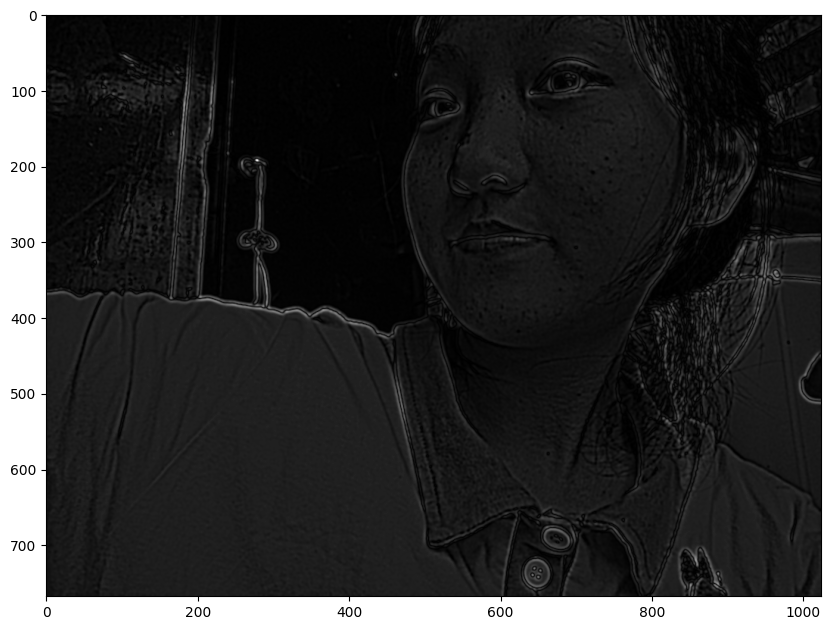

In [162]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
kernel = LoG(11)
print(np.around(kernel,decimals=2))
logGray =cv2.filter2D(gray,cv2.CV_64F,kernel)

print(np.around(logGray,decimals=2))
plt.figure(figsize=(10,10),dpi=100)
plt.imshow(np.abs(logGray),cmap='gray')
plt.show()

## DoG算子

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


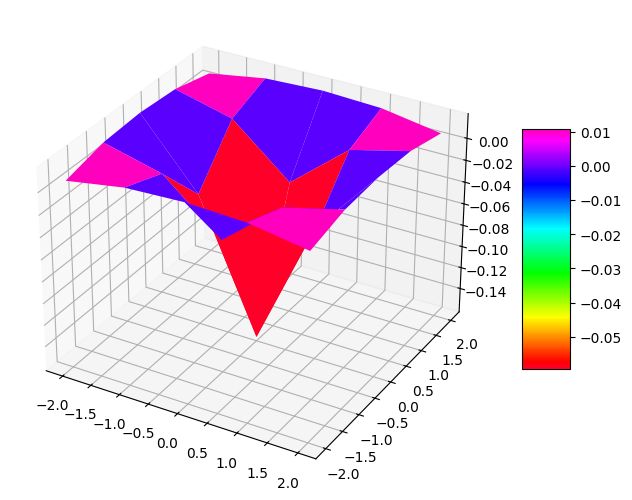

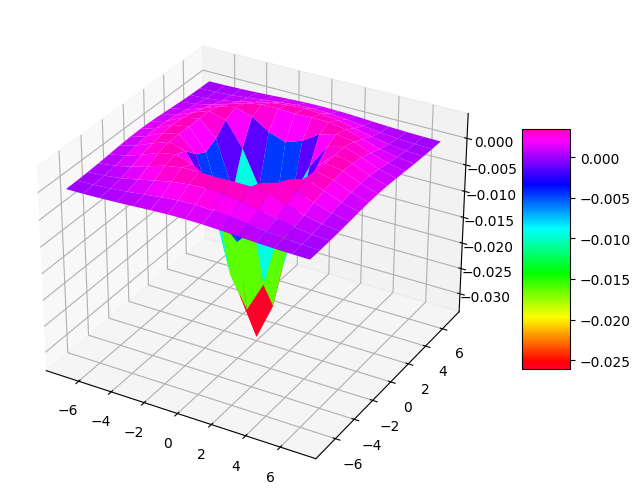

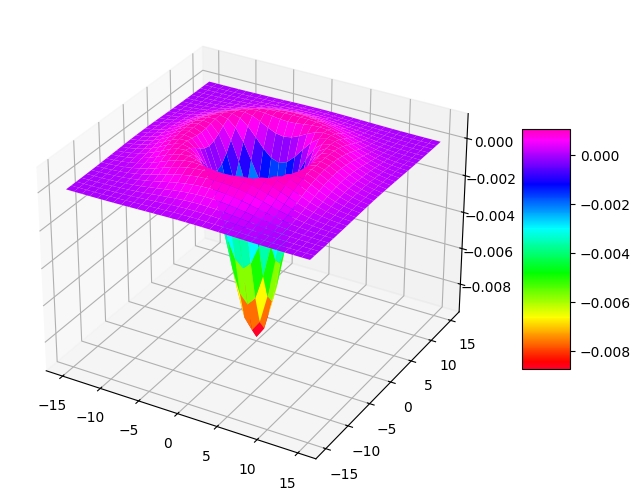

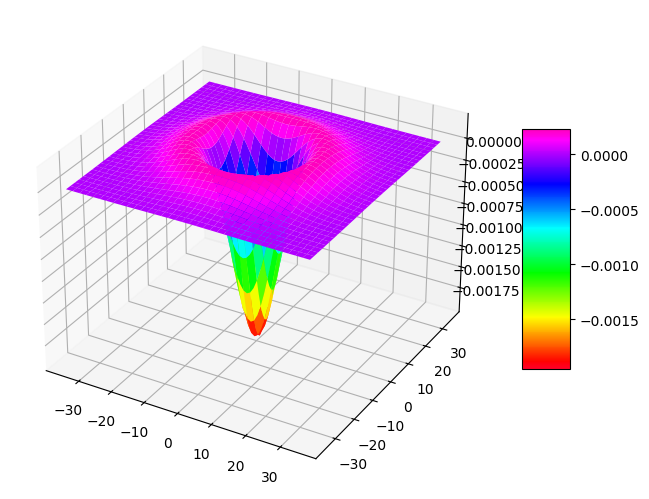

[[ 0.03 -0.01  0.03]
 [-0.01 -0.28 -0.01]
 [ 0.03 -0.01  0.03]]
[[ 0.01  0.02  0.02  0.02  0.01]
 [ 0.02  0.   -0.04  0.    0.02]
 [ 0.02 -0.04 -0.16 -0.04  0.02]
 [ 0.02  0.   -0.04  0.    0.02]
 [ 0.01  0.02  0.02  0.02  0.01]]
[[ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.01  0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.01  0.01  0.01  0.01  0.01  0.    0.    0.  ]
 [ 0.    0.    0.01  0.   -0.   -0.01 -0.    0.    0.01  0.    0.  ]
 [ 0.    0.    0.01 -0.   -0.02 -0.04 -0.02 -0.    0.01  0.    0.  ]
 [ 0.    0.01  0.01 -0.01 -0.04 -0.05 -0.04 -0.01  0.01  0.01  0.  ]
 [ 0.    0.    0.01 -0.   -0.02 -0.04 -0.02 -0.    0.01  0.    0.  ]
 [ 0.    0.    0.01  0.   -0.   -0.01 -0.    0.    0.01  0.    0.  ]
 [ 0.    0.    0.    0.01  0.01  0.01  0.01  0.01  0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.01  0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]
[[0. 0. 0.

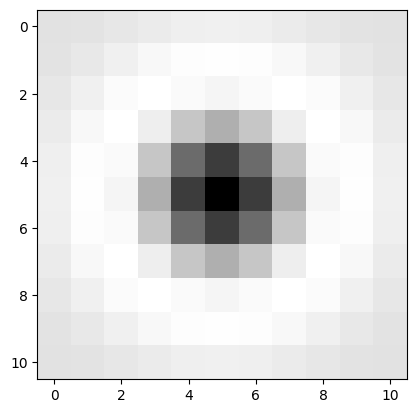

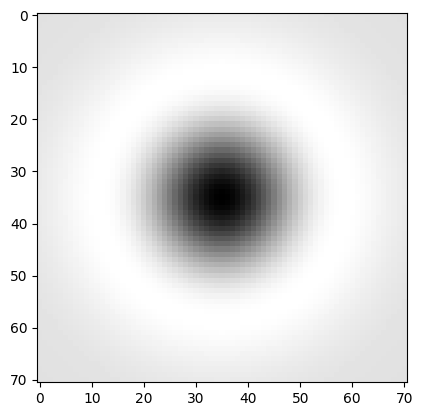

In [163]:
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

def Gaussian2D(x,y,sigma, mean=0):
    f = 1/(2*np.pi*sigma*sigma)*np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return f


def f_DoG(x,y,sigma=1.6):
    sigma1 = sigma
    sigma2 = sigma1/1.6
    result = Gaussian2D(x,y,sigma1)-Gaussian2D(x,y,sigma2)
    return result

def DoG(ksize=3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3+ 0.8
    
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    result = np.zeros((ksize,ksize),dtype = np.float64)
    for i in x:
        for j in y:
            #print(i,j)
            result[i+d,j+d] = f_DoG(i,j,sigma)    
    return result

def plotDoG(ksize = 3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3 + 0.8    
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    xx,yy = np.meshgrid(x,y)
    zz = DoG(ksize)
    fig = plt.figure()
    ax = Axes3D(fig) # 在窗口上添加3D坐标轴
    fig.add_axes(ax)#使用 ax = Axes3D(fig) ，将自身添加到图像中
    surf = ax.plot_surface(xx,yy,zz,cmap=cm.gist_rainbow)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()


print(np.around(DoG(71)))
plotDoG(5)
plotDoG(15)
plotDoG(31)
plotDoG(71)

print(np.around(DoG(3),decimals=2))
print(np.around(DoG(5),decimals=2))
print(np.around(DoG(11),decimals=2))
print(np.around(DoG(71),decimals=2))
plt.imshow(LoG(11),cmap='gray')
plt.show()


plt.imshow(DoG(71),cmap='gray')
plt.show()






## 绘制二维高斯函数

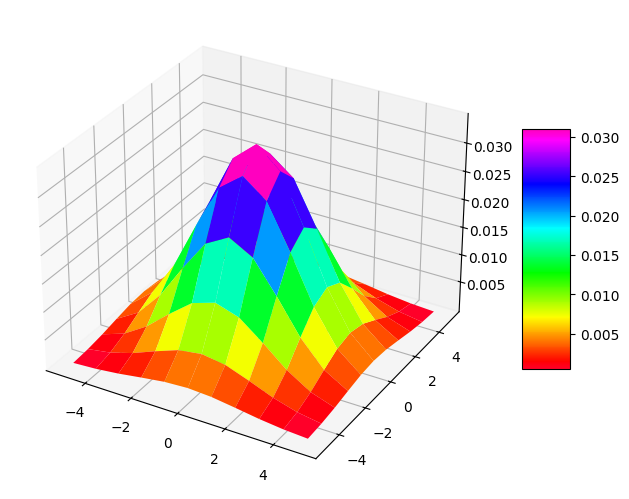

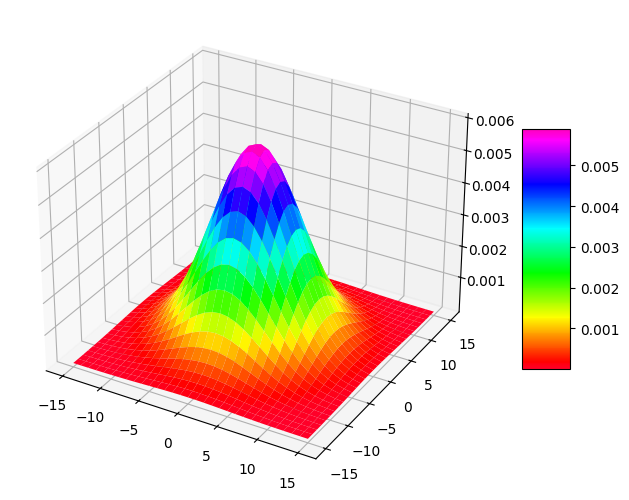

In [175]:
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

def Gaussian2D(x,y,sigma, mean=0):
    f = 1/(2*np.pi*sigma*sigma)*np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return f

def plotGaussian2D(ksize = 3):
    nx = ksize -1 
    sigma = (nx-1)/2*0.3 + 0.8    
    d = nx//2
    x = np.arange(-d,d+1)
    y = np.arange(-d,d+1)
    xx,yy = np.meshgrid(x,y)
    zz = Gaussian2D(xx,yy,sigma)
    fig = plt.figure()
    ax = Axes3D(fig) # 在窗口上添加3D坐标轴
    fig.add_axes(ax)#使用 ax = Axes3D(fig) ，将自身添加到图像中
    surf = ax.plot_surface(xx,yy,zz,cmap=cm.gist_rainbow)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()    



plotGaussian2D(11)

plotGaussian2D(31)

## example 9-12 使用DoG检测图像边缘

[[0.00881223]
 [0.02714358]
 [0.06511406]
 [0.12164907]
 [0.17699836]
 [0.20056541]
 [0.17699836]
 [0.12164907]
 [0.06511406]
 [0.02714358]
 [0.00881223]]
[[7.76553851e-05 2.39195426e-04 5.73799997e-04 1.07199952e-03
  1.55975010e-03 1.76742842e-03 1.55975010e-03 1.07199952e-03
  5.73799997e-04 2.39195426e-04 7.76553851e-05]
 [2.39195426e-04 7.36773780e-04 1.76742842e-03 3.30199100e-03
  4.80436855e-03 5.44406279e-03 4.80436855e-03 3.30199100e-03
  1.76742842e-03 7.36773780e-04 2.39195426e-04]
 [5.73799997e-04 1.76742842e-03 4.23984037e-03 7.92106463e-03
  1.15250810e-02 1.30596277e-02 1.15250810e-02 7.92106463e-03
  4.23984037e-03 1.76742842e-03 5.73799997e-04]
 [1.07199952e-03 3.30199100e-03 7.92106463e-03 1.47984970e-02
  2.15316860e-02 2.43985967e-02 2.15316860e-02 1.47984970e-02
  7.92106463e-03 3.30199100e-03 1.07199952e-03]
 [1.55975010e-03 4.80436855e-03 1.15250810e-02 2.15316860e-02
  3.13284183e-02 3.54997488e-02 3.13284183e-02 2.15316860e-02
  1.15250810e-02 4.80436855e-03 1

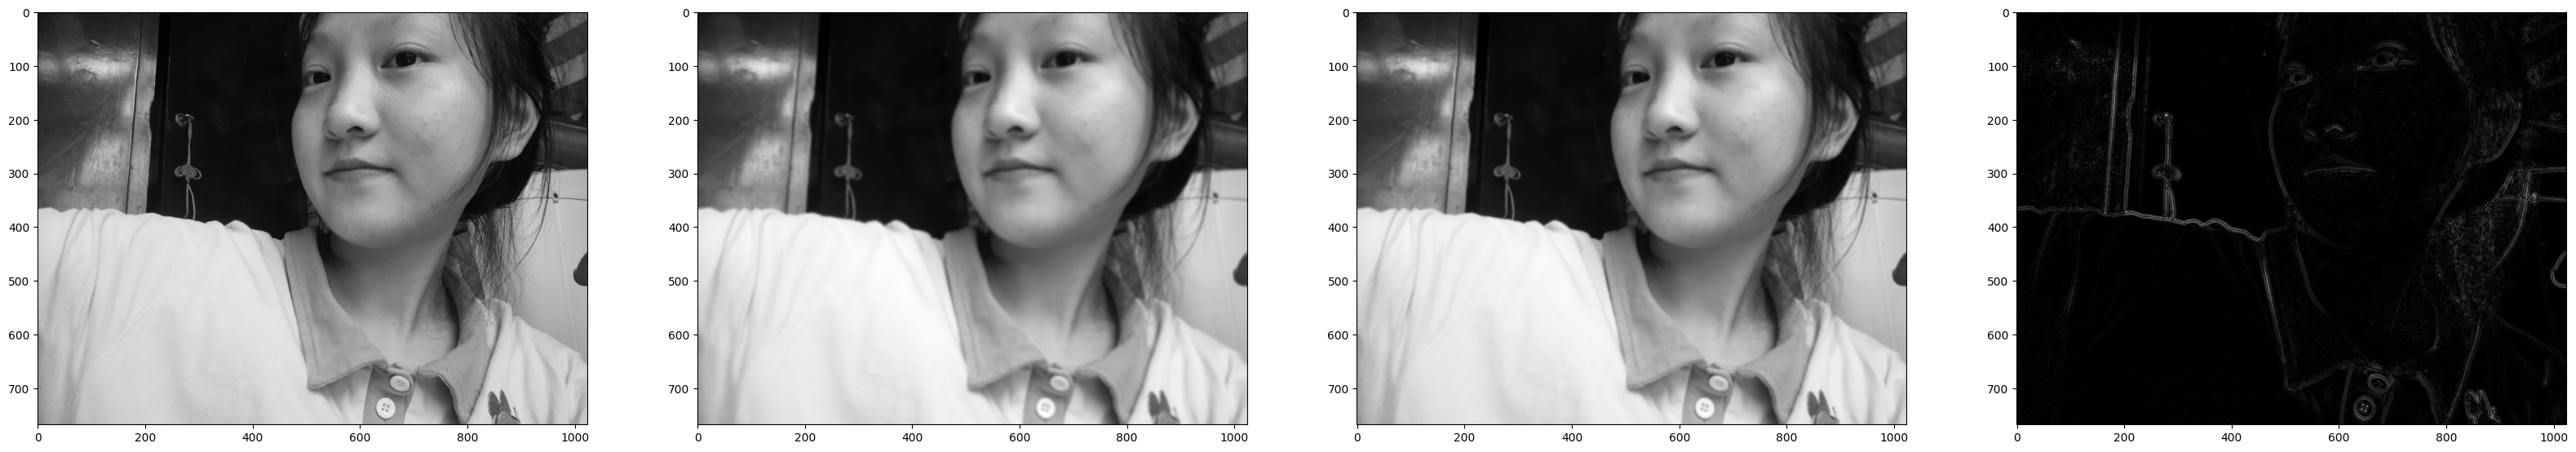

In [170]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 
from skimage import util

bgr = cv2.imread('/home/aistudio/weisuting.jpg')
b,g,r = cv2.split(bgr)
rgb  = cv2.merge([r,g,b] )
rgb = cv2.resize(rgb,(1024,768))
gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)


ksize = 11
k1d= cv2.getGaussianKernel(11,0)
k2d = k1d @ k1d.T
print(k1d)
print(k2d)
blur1 = cv2.filter2D(gray,cv2.CV_64F,k2d)

ksize = 7
k1d= cv2.getGaussianKernel(7,0)
k2d = k1d @ k1d.T
blur2 = cv2.filter2D(gray,cv2.CV_64F,k2d)
dogImg = blur1-blur2

fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,figsize=(40,10),dpi =100)
ax0.imshow(gray,cmap ='gray')
ax1.imshow(blur1,cmap = 'gray')
ax2.imshow(blur2,cmap ='gray')
ax3.imshow(np.abs(dogImg),cmap='gray')


请点击[此处](https://ai.baidu.com/docs#/AIStudio_Project_Notebook/a38e5576)查看本环境基本用法.  <br>
Please click [here ](https://ai.baidu.com/docs#/AIStudio_Project_Notebook/a38e5576) for more detailed instructions. 